# Shortest Path Queries on Riemannian Manifolds

In [2]:
%matplotlib inline
import time
import os, sys
#run from the repo root whether the kernel starts in notebooks/ or in the root
ROOT = os.path.abspath(".." if os.path.basename(os.getcwd()) == "notebooks" else ".")
os.chdir(ROOT)
sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt

from rgeo.manifolds import Euclidean, PoincareDisk, Terrain, GaussianHills
from rgeo.obstacles import Circle, Rectangle
from rgeo.graphs import build_graph, connected_comps, blocked
from rgeo.graphs import dijkstra, get_path
from rgeo.oracles.tree_decomposition import tree_decomposition
from rgeo.oracles import H2HIndex, MultiH2HIndex
from rgeo.oracles import SeparatorIndex, SeparatorContinuousIndex, SeparatorEikonalIndex, SeparatorHeatIndex, SeparatorRefinedIndex, SeparatorEikonalLeafIndex, SeparatorCutIndex, SeparatorBFSRefinedIndex
from rgeo.solvers.eikonal import solve_eikonal, anisotropy_ratio, sample_field
from rgeo.refine import refine_path, refine_polyline
from rgeo.graphs import sampling as ad
from rgeo import visualize as vz
rng = np.random.default_rng(0)
plt.rcParams["figure.dpi"] = 300

## Discreatizing a Riemannian manifold

Rectangle grid

7668 nodes,  59982 edges


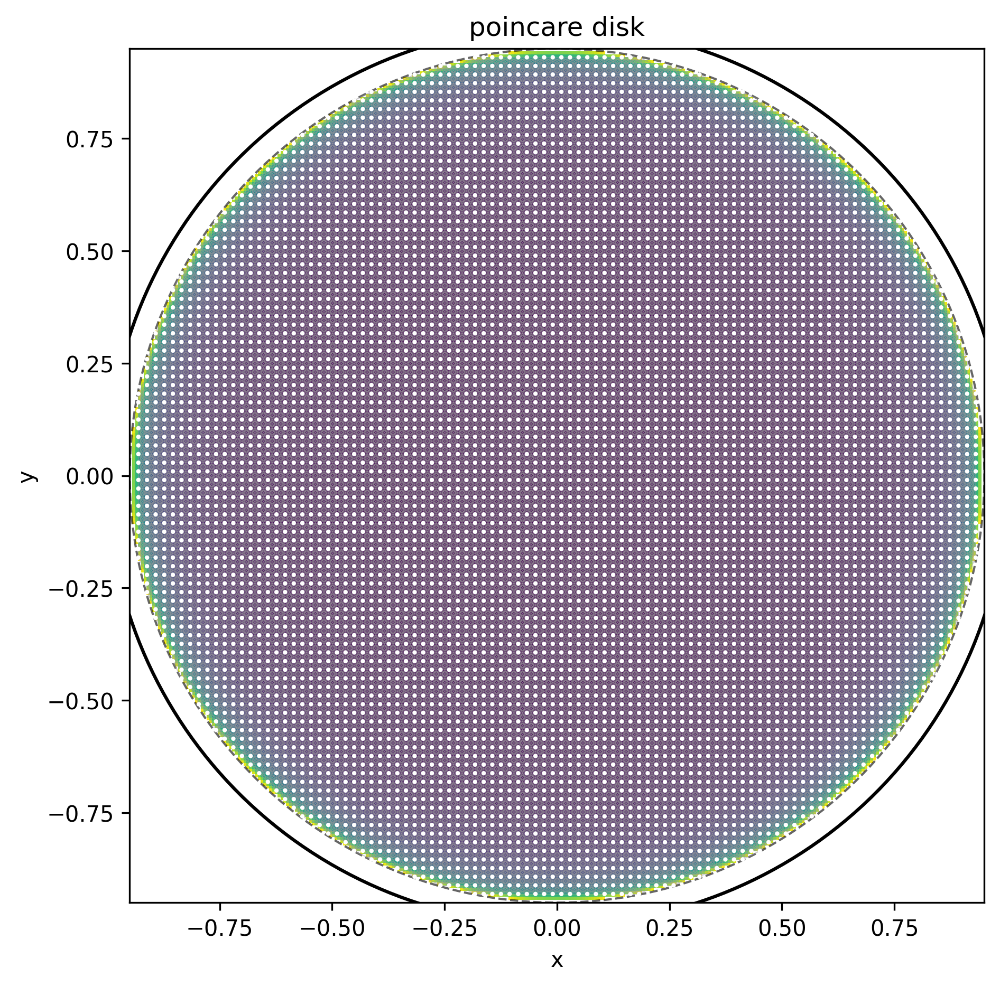

In [3]:
manifold = PoincareDisk(rmax=0.95)
bounds = (-0.95, 0.95, -0.95, 0.95)

points, adj = build_graph(manifold, bounds, 100, 100)
print(f"{len(points)} nodes,  {sum(len(a) for a in adj)//2} edges")
fig, ax = vz.visualize_query(manifold, bounds, points, adj, title="poincare disk")
plt.show()

Triangular grid

1958 nodes,  5713 edges


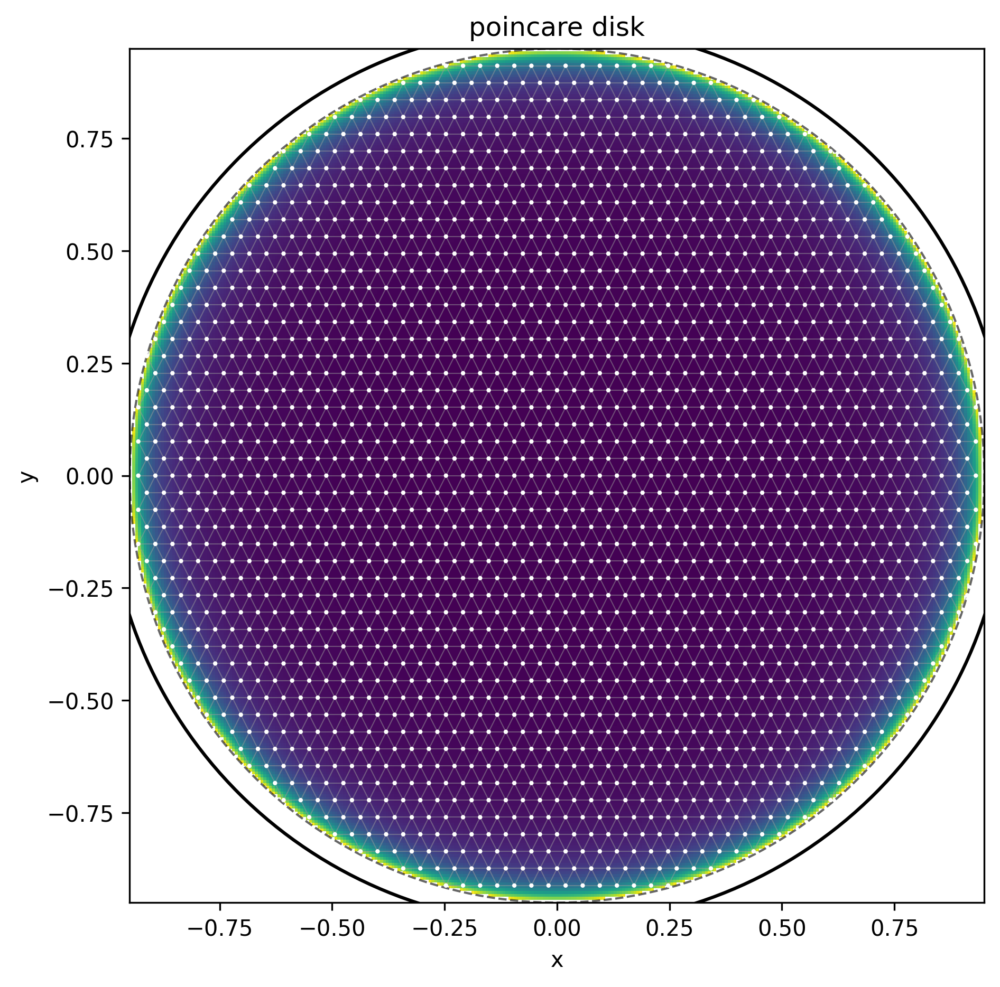

In [3]:
points_triang, adj_triang = build_graph(manifold, bounds, 50, 50, type="triangular")
print(f"{len(points_triang)} nodes,  {sum(len(a) for a in adj_triang)//2} edges")
fig, ax = vz.visualize_query(manifold, bounds, points_triang, adj_triang, title="poincare disk")
plt.show()

## Graph distance vs exact geodesic

In [4]:
def bench_queries(adj, points, exact_dist, n_pairs=300, n_time=2000, seed=1):
    t0 = time.perf_counter()
    idx = H2HIndex(adj)
    build_time = (time.perf_counter() - t0)
    
    n = len(points)
    g = np.random.default_rng(seed)
    d_exact, d_graph = [], []
    
    while len(d_exact) < n_pairs:
        s, t = int(g.integers(n)), int(g.integers(n))
        if s == t:
            continue
        d_exact.append(exact_dist(points[s], points[t]))
        d_graph.append(idx.query(s, t))
    d_exact, d_graph = np.array(d_exact), np.array(d_graph)
    rel = np.abs(d_graph - d_exact) / d_exact

    pairs = [(int(g.integers(n)), int(g.integers(n))) for _ in range(n_time)]
    t0 = time.perf_counter()
    for s, t in pairs:
        idx.query(s, t)
    q_time = (time.perf_counter() - t0) / n_time

    return {"idx": idx, "n": n, "mean": rel.mean(), "max": rel.max(), "build_time": build_time, "query_time": q_time}


points, adj = build_graph(manifold, bounds, 100, 100, [], type="rectangle")
points_triang, adj_triang = build_graph(manifold, bounds, 160, 160, [], type="triangular")

for label, pts, a in [("rectangle", points, adj), ("triangular", points_triang, adj_triang)]:
    r = bench_queries(a, pts, PoincareDisk.exact_dist)
    print(f"{label} ({r['n']} nodes): mean err {r['mean']}, max {r['max']}, build {r['build_time']}, query {r['query_time']}")

rectangle (7668 nodes): mean err 0.008642787189601688, max 0.026589534594892255, build 37.12853820901364, query 8.885249961167574e-06
triangular (20097 nodes): mean err 0.07798701363772702, max 0.1690020796722568, build 31.863409499870613, query 1.5659478958696126e-05


## Shortest Path Query

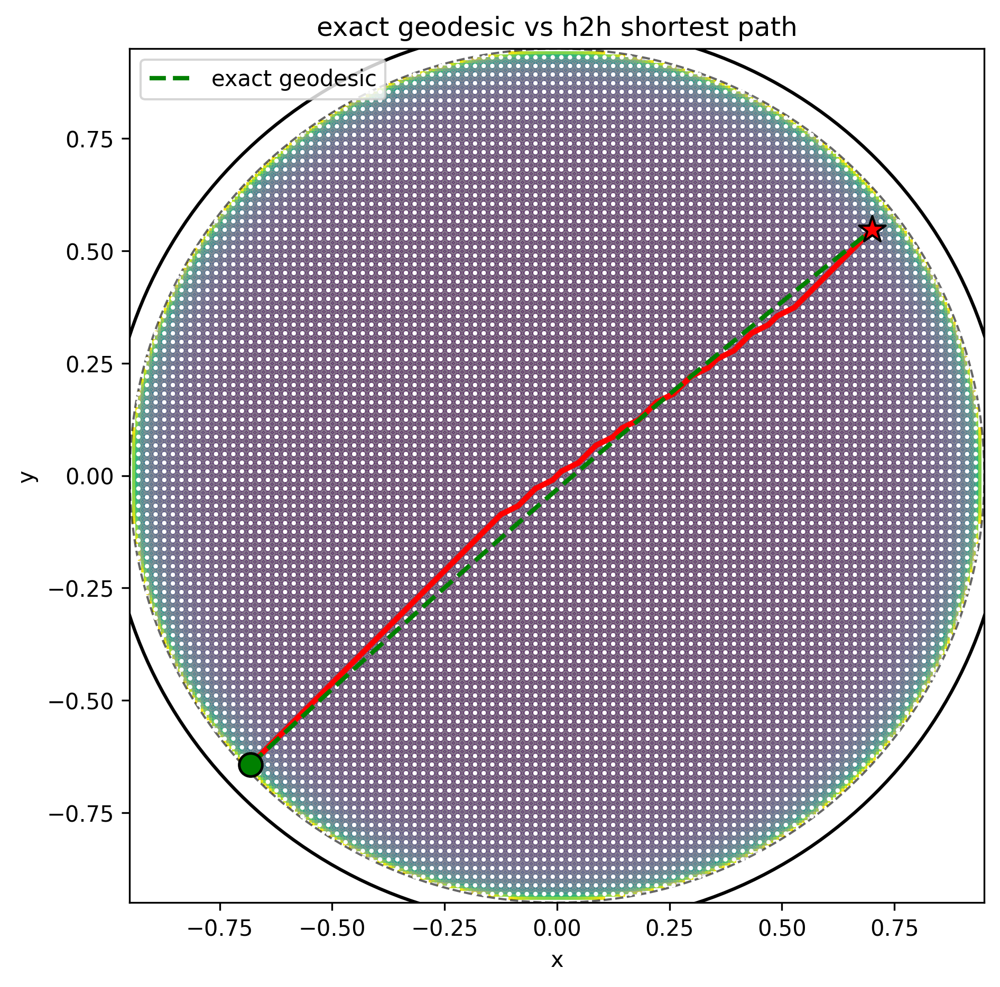

h2h graph distance: 6.296047222528944
exact hyperbolic: 6.251814832886787


In [5]:
def nearest_node(points, xy):
    return int(np.argmin(np.sum((points - np.asarray(xy, float)) ** 2, axis=1)))

manifold = PoincareDisk(rmax=0.95)
bounds = (-0.95, 0.95, -0.95, 0.95)
points, adj = build_graph(manifold, bounds, 100, 100)
idx = H2HIndex(adj)

s = nearest_node(points, (-0.7, -0.65))
t = nearest_node(points, (0.7, 0.55))
dist, path = idx.query_path(s, t)

fig, ax = vz.visualize_query(manifold, bounds, points, adj, path=path, title=f"exact geodesic vs h2h shortest path")
vz.plot_polyline(ax, manifold.exact_geodesic(points[s], points[t], 120), color="green", ls="--", lw=2.0, label="exact geodesic")
ax.legend(loc="upper left")
plt.show()
print("h2h graph distance:", dist)
print("exact hyperbolic:", PoincareDisk.exact_dist(points[s], points[t]))


dist: 9.49129421982213


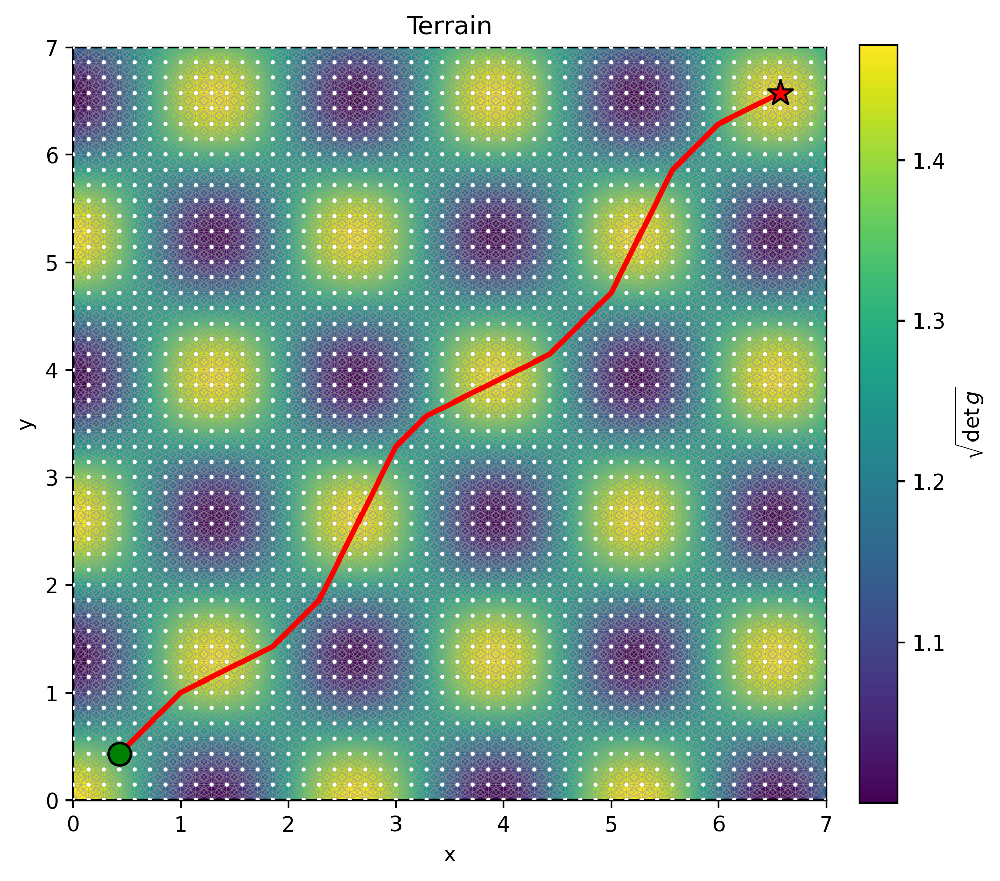

In [6]:
manifold = Terrain(amp=0.9, freq=1.2)
bounds = (0, 7, 0, 7)
points, adj = build_graph(manifold, bounds, 50, 50, [])
idx = H2HIndex(adj)

s = nearest_node(points, (0.4, 0.4)); t = nearest_node(points, (6.6, 6.6))
dist, path = idx.query_path(s, t)
fig, ax = vz.visualize_query(manifold, bounds, points, adj, path=path, colorbar=True, title=f"Terrain")
print("dist:", dist)
plt.show()

## Shortest path with obstacles

dist: 13.879243922850861


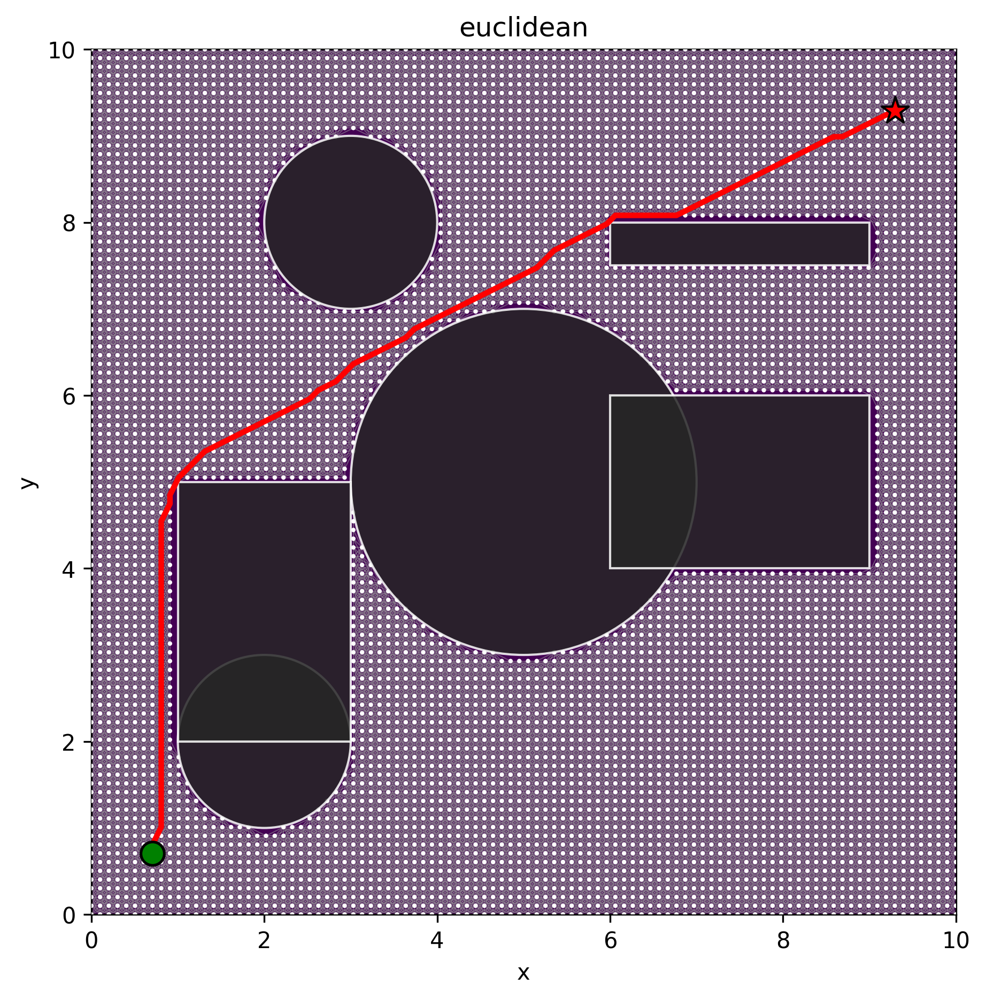

In [8]:
manifold = Euclidean()
bounds = (0, 10, 0, 10)
obstacles = [Circle(5, 5, 2.0), Circle(3.0, 8.0, 1.0), Rectangle(6, 9, 7.5, 8), Circle(2, 2, 1.0), Rectangle(1, 3, 2, 5), Rectangle(6, 9, 4, 6)]
points, adj = build_graph(manifold, bounds, 100, 100, obstacles)
idx = H2HIndex(adj)

s = nearest_node(points, (0.7, 0.7)); t = nearest_node(points, (9.3, 9.3))
dist, path = idx.query_path(s, t)
fig, ax = vz.visualize_query(manifold, bounds, points, adj, obstacles=obstacles, path=path, title=f"euclidean")
print("dist:", dist)
plt.show()

dist: 13.066419571562408


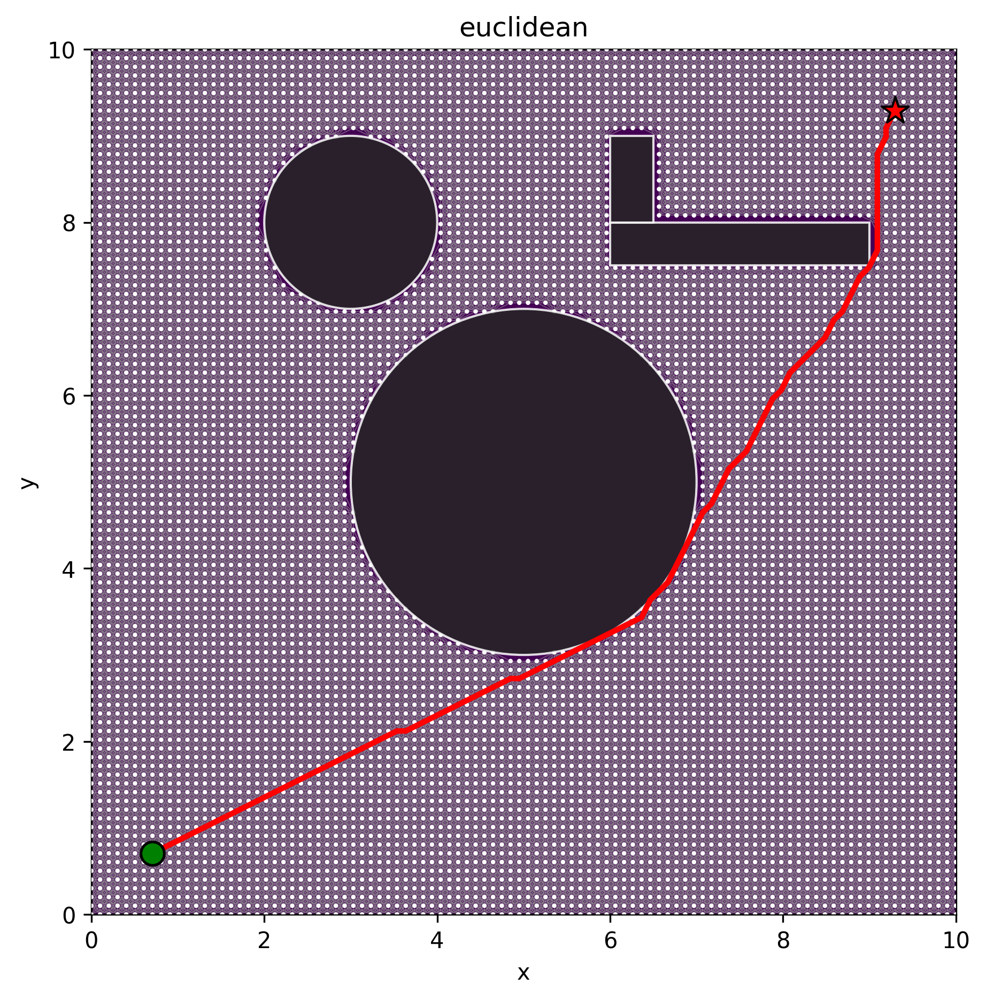

In [8]:
manifold = Euclidean()
bounds = (0, 10, 0, 10)
obstacles = [Circle(5, 5, 2.0), Circle(3.0, 8.0, 1.0), Rectangle(6, 9, 7.5, 8), Rectangle(6, 6.5, 8, 9)]
points, adj = build_graph(manifold, bounds, 100, 100, obstacles)
idx = H2HIndex(adj)

s = nearest_node(points, (0.7, 0.7)); t = nearest_node(points, (9.3, 9.3))
dist, path = idx.query_path(s, t)
fig, ax = vz.visualize_query(manifold, bounds, points, adj, obstacles=obstacles, path=path, title=f"euclidean")
print("dist:", dist)
plt.show()


nodes: 2220
edges: 16483
index build time: 1992.5254590343684 ms
tree height h: 458
treewidth w: 139
total label entries: 604279
avg labels per vertex: 272.19774774774777
dijkstra: 0.004822655834024772 per query
h2h query: 8.241458097472786e-06 per query
speed-up: 585.1702183019802x


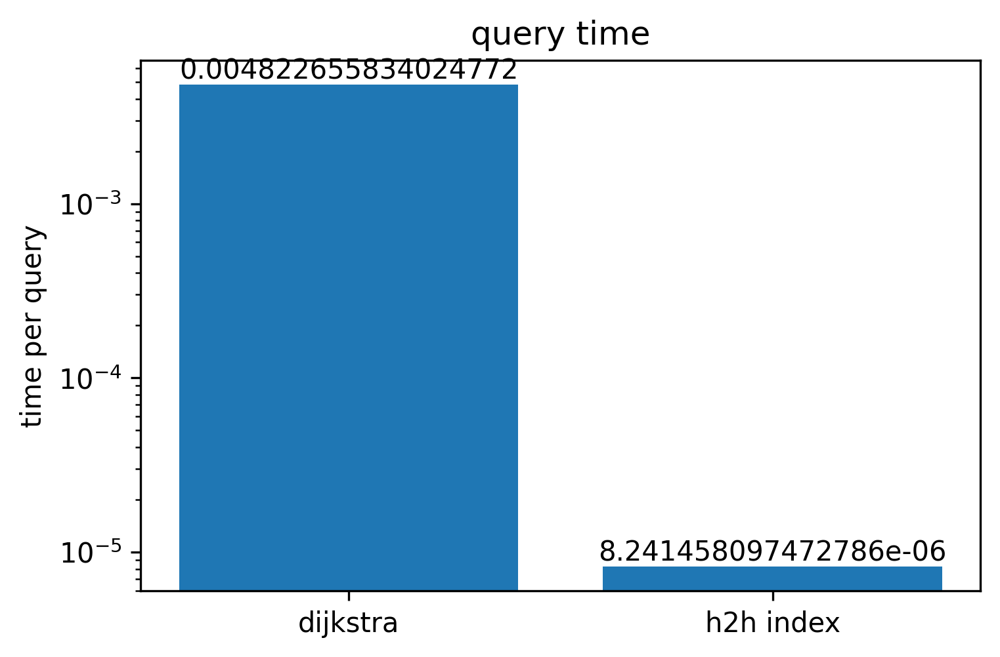

In [9]:
manifold = Euclidean()
bounds = (0, 12, 0, 12)
obstacles = [Circle(6, 6, 2.0), Rectangle(1.5, 3.0, 7.0, 10.0)]
points, adj = build_graph(manifold, bounds, 50, 50, obstacles)
n = len(points)
t0 = time.perf_counter()
idx = H2HIndex(adj)
build_ms = (time.perf_counter() - t0) * 1e3

print(f"nodes: {n}")
print(f"edges: {sum(len(a) for a in adj)//2}")
print(f"index build time: {build_ms} ms")
print(f"tree height h: {idx.h}")
print(f"treewidth w: {idx.width - 1}")
print(f"total label entries: {idx.label_entries}")
print(f"avg labels per vertex: {idx.label_entries / n}")

pairs = [(int(rng.integers(n)), int(rng.integers(n))) for _ in range(1000)]

t0 = time.perf_counter()
for s, t in pairs:
    dijkstra(adj, s, t)
dij_time = (time.perf_counter() - t0) / len(pairs)

t0 = time.perf_counter()
for s, t in pairs:
    idx.query(s, t)
h2h_time = (time.perf_counter() - t0) / len(pairs)

print(f"dijkstra: {dij_time} per query")
print(f"h2h query: {h2h_time} per query")
print(f"speed-up: {dij_time / h2h_time}x")

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.bar(["dijkstra", "h2h index"], [dij_time, h2h_time])
ax.set_yscale("log")
ax.set_ylabel("time per query")
ax.set_title(f"query time")
for i, v in enumerate([dij_time, h2h_time]):
    ax.text(i, v, f"{v}", ha="center", va="bottom")
plt.show()



## Multiple connected components

Generally H2H indexing applied on a graph with one connected component, but an obsticle can split the graph into multiple connected components. So we solve this:

1. label every vertex with its connected component (bfs)
2. build an independent h2h index per component
3. a query first checks whether $s$ and $t$ share a component:
    1) if different components then distance is inf and no path
    2) else if same component then we do query on this component


2 connected components, sizes = [4500, 4500]
same component: False
(1.0, 1.0) to (3.5, 9.0): d=8.575929236110577
(6.5, 1.0) to (9.0, 9.0): d=8.575929236110577


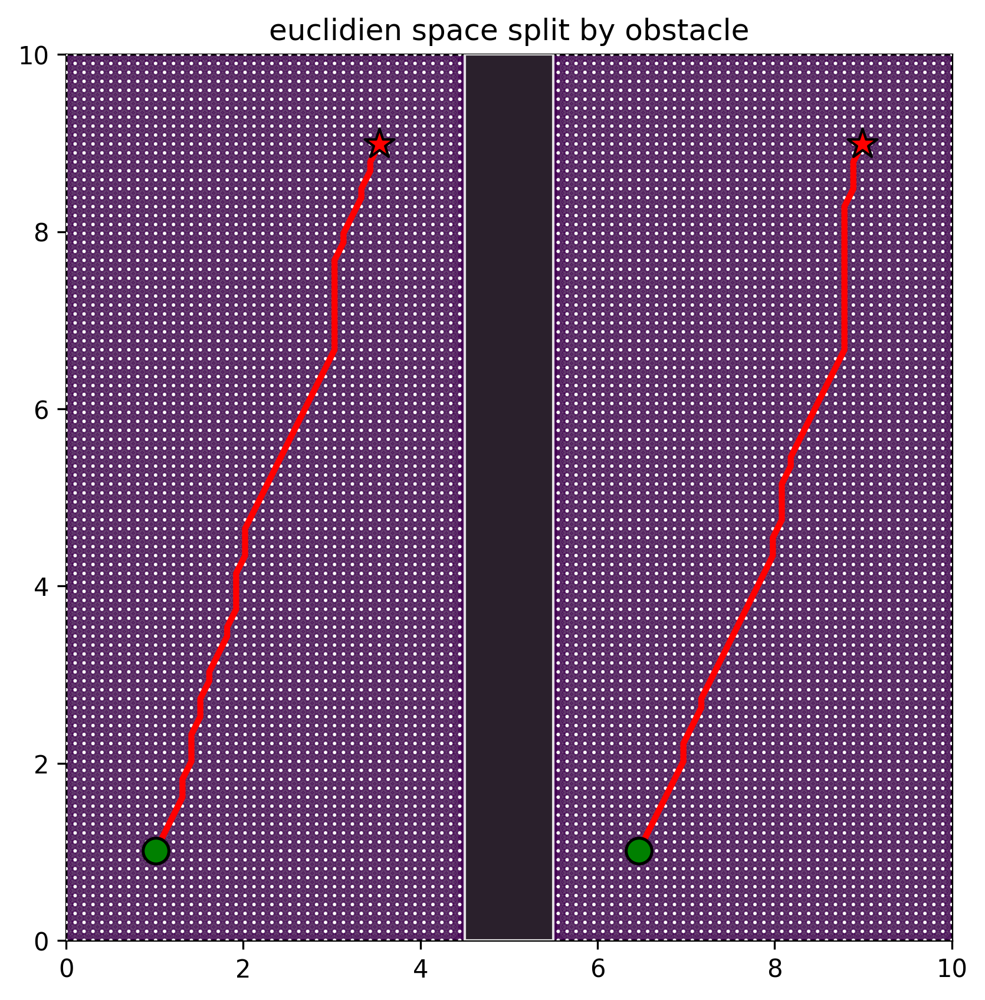

In [10]:
mani = Euclidean()
bounds = (0, 10, 0, 10)
wall = [Rectangle(4.5, 5.5, 0, 10.0)]
points, adj = build_graph(mani, bounds, 100, 100, wall)
comp, members = connected_comps(adj)
mindex = MultiH2HIndex(adj)
print(f"{len(members)} connected components, sizes = {sorted(len(m) for m in members)}")

s_left  = nearest_node(points, (1.5, 5.0))
t_right = nearest_node(points, (8.5, 5.0))
print("same component:", mindex.same_component(s_left, t_right))

fig, ax = plt.subplots(figsize=(6.5, 6.5))
vz.plot_background(ax, mani, bounds, res=180)
vz.plot_obstacles(ax, wall)
vz.plot_graph(ax, points, adj, node_size=2, edge_alpha=0.2)

for (a, b) in [(((1.0, 1.0), (3.5, 9.0))), (((6.5, 1.0), (9.0, 9.0)))]:
    s = nearest_node(points, a)
    t = nearest_node(points, b)
    d, path = mindex.query_path(s, t)
    vz.plot_path(ax, points, path)
    print(f"{a} to {b}: d={d}")

ax.set_xlim(bounds[0], bounds[1])
ax.set_ylim(bounds[2], bounds[3])
ax.set_aspect("equal")
ax.set_title("euclidien space split by obstacle")
plt.show()


## Adaptive sampling

Instead of sampling uniformly, choose sampling density $\rho(x)$

$$\rho(x)\ \propto\ w_g\,\lVert\nabla g(x)\rVert \;+\; w_k\,\lvert K(x)\rvert \;+\; w_o\,e^{-\,d_g(x,\partial O)/\sigma},$$

more samples where the metric changes fast, where the curvature is high, and
near obstacle boundaries. $V_{ad}=V_{int}\cup V_{\partial O}$:

6986 nodes


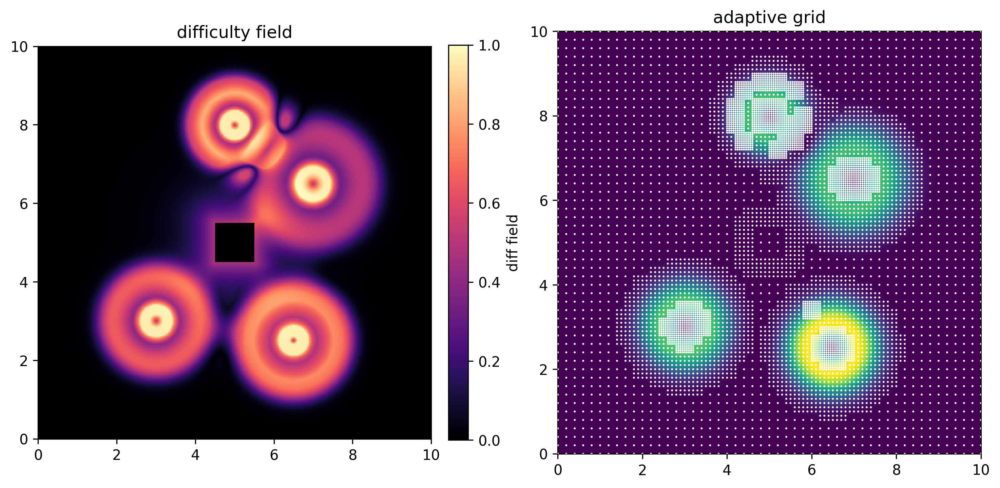

In [10]:
hills = [(3.0, 3.0, 2.2, 0.6), (7.0, 6.5, 2.5, 0.7), (5.0, 8.0, 1.8, 0.5), (6.5, 2.5, 2.8, 0.6)]
mani = GaussianHills(hills)
bounds = (0, 10, 0, 10)
obstacles = [Rectangle(4.5, 5.5, 4.5, 5.5)]
diff_field = ad.difficulty_field(mani, bounds, obstacles, res=300)
xs, ys, d = diff_field
pts_ad, adj_ad = ad.build_adaptive_graph(mani, bounds, [], n0=50, max_levels=3, tau=0.4, k=8, field=diff_field)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
vz.plot_field(axes[0], xs, ys, d, manifold=mani, colorbar=True)
axes[0].set_title(r"difficulty field")
vz.plot_background(axes[1], mani, bounds, res=140)
vz.plot_graph(axes[1], pts_ad, adj_ad, node_size=2, edge_alpha=0)
axes[1].set_title(f"adaptive grid")

print(f"{len(pts_ad)} nodes")
for a in axes:
    a.set_xlim(0, 10)
    a.set_ylim(0, 10)
    a.set_aspect("equal")
plt.show()


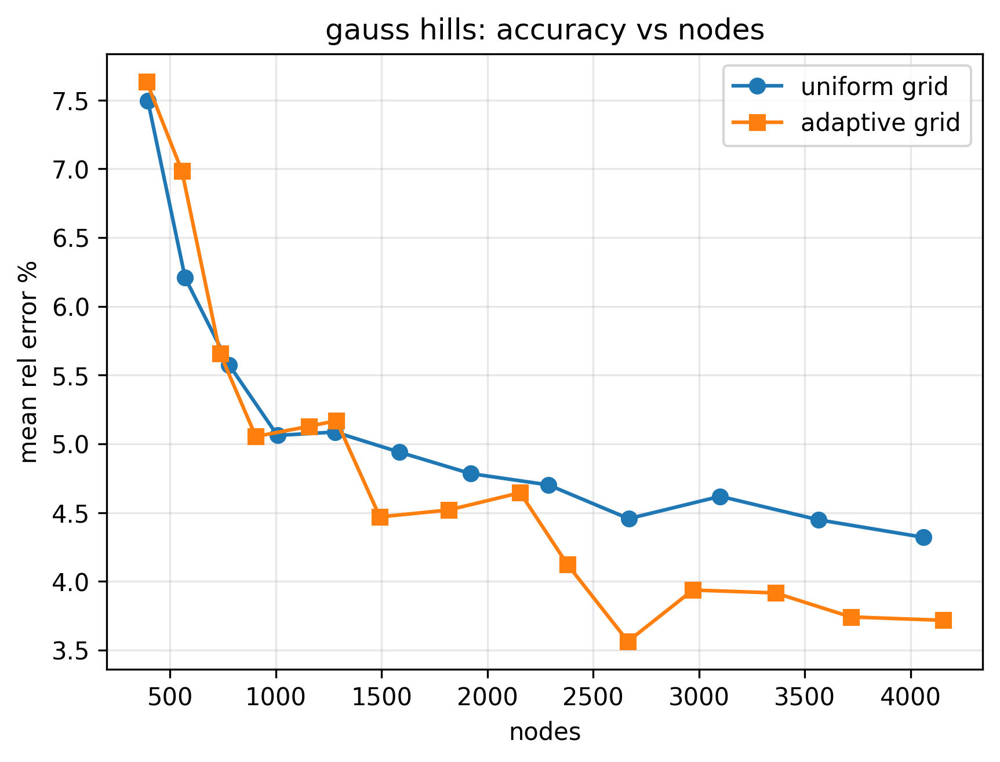

In [12]:
n = 50
rng = np.random.default_rng(2)
query_points = []
while len(query_points) < n:
    p = rng.uniform([0.3, 0.3], [9.7, 9.7])
    if manifold.in_domain(p) and not blocked(p, obstacles):
        query_points.append(p)
        
query_points = np.array(query_points)
pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]
ref_points, ref_adj = ad.build_uniform_graph(manifold, bounds, 200, 200, obstacles, k=24)
ref_ids = [nearest_node(ref_points, p) for p in query_points]
ref_from = [dijkstra(ref_adj, i)[0] for i in ref_ids]
ref_dist = {(i, j): ref_from[i][ref_ids[j]] for i, j in pairs}

def graph_error(points, adj):
    index = MultiH2HIndex(adj)
    nearest_points = [nearest_node(points, p) for p in query_points]
    rel_err = [abs(index.query(nearest_points[i], nearest_points[j]) - ref_dist[(i, j)]) / ref_dist[(i, j)] for (i, j) in pairs if index.same_component(nearest_points[i], nearest_points[j]) and ref_dist[(i, j)] > 0]
    return np.array(rel_err)

uniform = []
for R in (20, 24, 28, 32, 36, 40, 44, 48, 52, 56, 60, 64):
    points_uni, adj_uni = ad.build_uniform_graph(manifold, bounds, R, R, obstacles, k=12)
    uniform.append((len(points_uni), graph_error(points_uni, adj_uni).mean()))

adaptive = []
for n0 in (10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38):
    points_ad, adj_ad = ad.build_adaptive_graph(manifold, bounds, obstacles, n0=n0, max_levels=3, tau=0.4, k=12, field=diff_field)
    adaptive.append((len(points_ad), graph_error(points_ad, adj_ad).mean()))

fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.plot([u[0] for u in uniform], [u[1] * 100 for u in uniform], "o-", label="uniform grid")
ax.plot([u[0] for u in adaptive], [u[1] * 100 for u in adaptive], "s-", label="adaptive grid")
ax.set_xlabel("nodes")
ax.set_ylabel("mean rel error %")
ax.set_title("gauss hills: accuracy vs nodes")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

7317 nodes


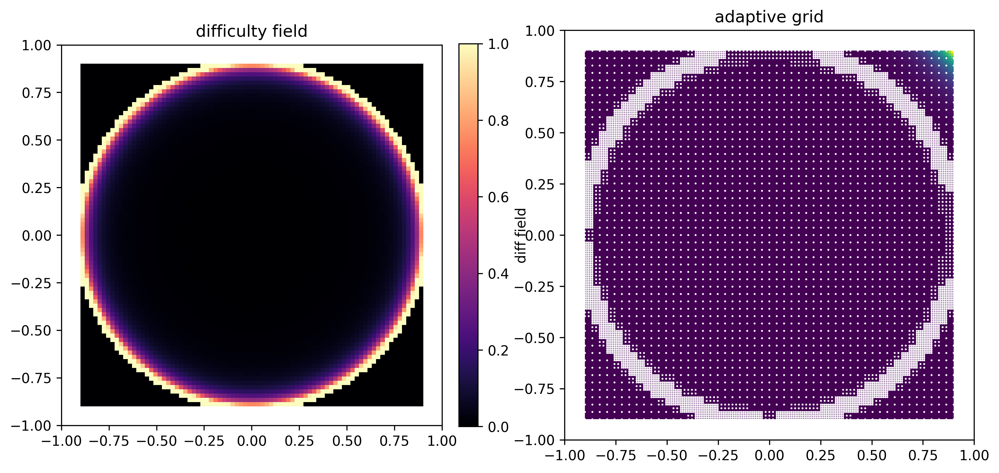

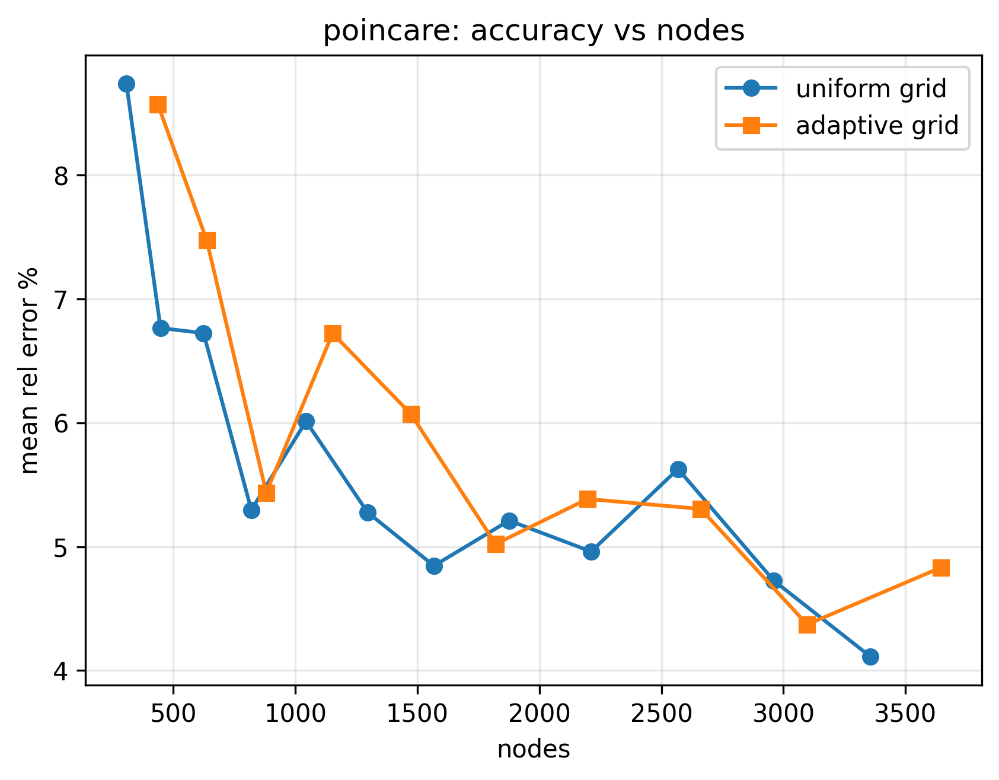

In [13]:
manifold = PoincareDisk(rmax=0.94)
bounds = (-0.9, 0.9, -0.9, 0.9)
diff_field = ad.difficulty_field(manifold, bounds, [], res=80, weights=(1.0, 0.0, 0.0))

xs, ys, d = diff_field
pts_ad, adj_ad = ad.build_adaptive_graph(mani, bounds, [], n0=50, max_levels=3, tau=0.4, k=8, field=diff_field)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
vz.plot_field(axes[0], xs, ys, d, manifold=mani, colorbar=True)
axes[0].set_title(r"difficulty field")
vz.plot_background(axes[1], mani, bounds, res=140)
vz.plot_graph(axes[1], pts_ad, adj_ad, node_size=2, edge_alpha=0)
axes[1].set_title(f"adaptive grid")

print(f"{len(pts_ad)} nodes")
for a in axes:
    a.set_xlim(-1, 1)
    a.set_ylim(-1, 1)
    a.set_aspect("equal")
plt.show()

n = 50
rng = np.random.default_rng(2)
query_points = []
while len(query_points) < n:
    p = rng.uniform(-0.85, 0.85, 2)
    if manifold.in_domain(p):
        query_points.append(p)
query_points = np.array(query_points)
pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]
exact_dist = {(i, j): PoincareDisk.exact_dist(query_points[i], query_points[j]) for i, j in pairs}


def graph_error_poincare(points, adj):
    index = MultiH2HIndex(adj)
    nearest_points = [nearest_node(points, p) for p in query_points]
    rel_err = [abs(index.query(nearest_points[i], nearest_points[j]) - exact_dist[(i, j)]) / exact_dist[(i, j)] for (i, j) in pairs if index.same_component(nearest_points[i], nearest_points[j])]
    return np.array(rel_err)


uniform, adaptive = [], []
for R in (20, 24, 28, 32, 36, 40, 44, 48, 52, 56, 60, 64):
    points_uni, adj_uni = ad.build_uniform_graph(manifold, bounds, R, R, [], k=8)
    uniform.append((len(points_uni), graph_error_poincare(points_uni, adj_uni).mean()))
for n0 in (16, 20, 24, 28, 32, 36, 40, 44, 48, 52):
    points_ad, adj_ad = ad.build_adaptive_graph(manifold, bounds, [], n0=n0, max_levels=1, tau=0.33, k=8, field=diff_field)
    adaptive.append((len(points_ad), graph_error_poincare(points_ad, adj_ad).mean()))

fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.plot([u[0] for u in uniform], [u[1] * 100 for u in uniform], "o-", label="uniform grid")
ax.plot([u[0] for u in adaptive], [u[1] * 100 for u in adaptive], "s-", label="adaptive grid")
ax.set_xlabel("nodes")
ax.set_ylabel("mean rel error %")
ax.set_title("poincare: accuracy vs nodes")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## Sampling on a boundary

In [14]:
def exact_around_disk(s, t, c, r):
    s = np.asarray(s, float)
    t = np.asarray(t, float)
    c = np.asarray(c, float)
    d = t - s; 
    f = s - c
    a = d @ d; 
    b = 2 * f @ d
    disc = b * b - 4 * a * (f @ f - r * r)
    hit = False
    
    if disc > 0:
        sq = np.sqrt(disc)
        t1 = (-b - sq) / (2 * a)
        t2 = (-b + sq) / (2 * a)
        hit = (0 < t1 < 1) or (0 < t2 < 1)
    if not hit:
        return np.linalg.norm(t - s)
    
    ds = np.linalg.norm(s - c)
    dt = np.linalg.norm(t - c)
    ls = np.sqrt(max(ds * ds - r * r, 0))
    lt = np.sqrt(max(dt * dt - r * r, 0))
    ang = np.arccos(np.clip((s - c) @ (t - c) / (ds * dt), -1, 1))
    arc = max(ang - np.arccos(np.clip(r / ds, -1, 1)) - np.arccos(np.clip(r / dt, -1, 1)), 0.0)
    return ls + lt + r * arc

manifold = Euclidean()
bounds = (0, 10, 0, 10)
c = (5.0, 5.0)
r = 2.3
obstacles = [Circle(c[0], c[1], r)]
Vb = ad.samlpe_boundary_points(manifold, obstacles, bounds, offset=0.01, spacing=0.1)

n = 60
rng = np.random.default_rng(11)
query_points = []
while len(query_points) < n:
    p = rng.uniform([0.1, 0.1], [9.9, 9.9])
    if not blocked(p, obstacles):
        query_points.append(p)
query_points = np.array(query_points)

pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]
exact_dist = {(i, j): exact_around_disk(query_points[i], query_points[j], c, r) for i, j in pairs}
affected_points = [(i, j) for i, j in pairs if exact_dist[(i, j)] > np.linalg.norm(query_points[i] - query_points[j]) + 1e-9]


def affected_points_error(points, adj):
    index = MultiH2HIndex(adj)
    nearest_points = [nearest_node(points, p) for p in query_points]
    rel_err = [abs(index.query(nearest_points[i], nearest_points[j]) - exact_dist[(i, j)]) / exact_dist[(i, j)] for (i, j) in affected_points if index.same_component(nearest_points[i], nearest_points[j])]
    return np.array(rel_err)


points_uni, adj_uni = ad.build_uniform_graph(manifold, bounds, 200, 200, obstacles, k=8)
points_uni_bound, adj_uni_bound = ad.graph_from_points(manifold, points_uni + Vb, obstacles, k=12)
rel_err_uni = affected_points_error(points_uni, adj_uni)
rel_err_uni_bound = affected_points_error(points_uni_bound, adj_uni_bound)

print(f"uniform ({len(points_uni)} nodes): mean {rel_err_uni.mean()}, p95 {np.percentile(rel_err_uni, 95)}, max {rel_err_uni.max()}")
print(f"uniform + V_dO ({len(points_uni_bound)} nodes): mean {rel_err_uni_bound.mean()}, p95 {np.percentile(rel_err_uni_bound, 95)}, max {rel_err_uni_bound.max()}")

uniform (33416 nodes): mean 0.050756973189798514, p95 0.07063678237512196, max 0.07959592713902741
uniform + V_dO (33561 nodes): mean 0.035705801321939346, p95 0.05861930854493688, max 0.06712770849950825


some examples of the path 

path 1: exact dist: 9.650023363125968, h2h dist: 10.070085624739168
path 2: exact dist: 9.71275609891411, h2h dist: 10.087570561062808
path 3: exact dist: 8.33359632407566, h2h dist: 8.45890798537511
path 4: exact dist: 10.134699033136691, h2h dist: 10.617159607200911
path 5: exact dist: 9.922123986460818, h2h dist: 10.0839993142354


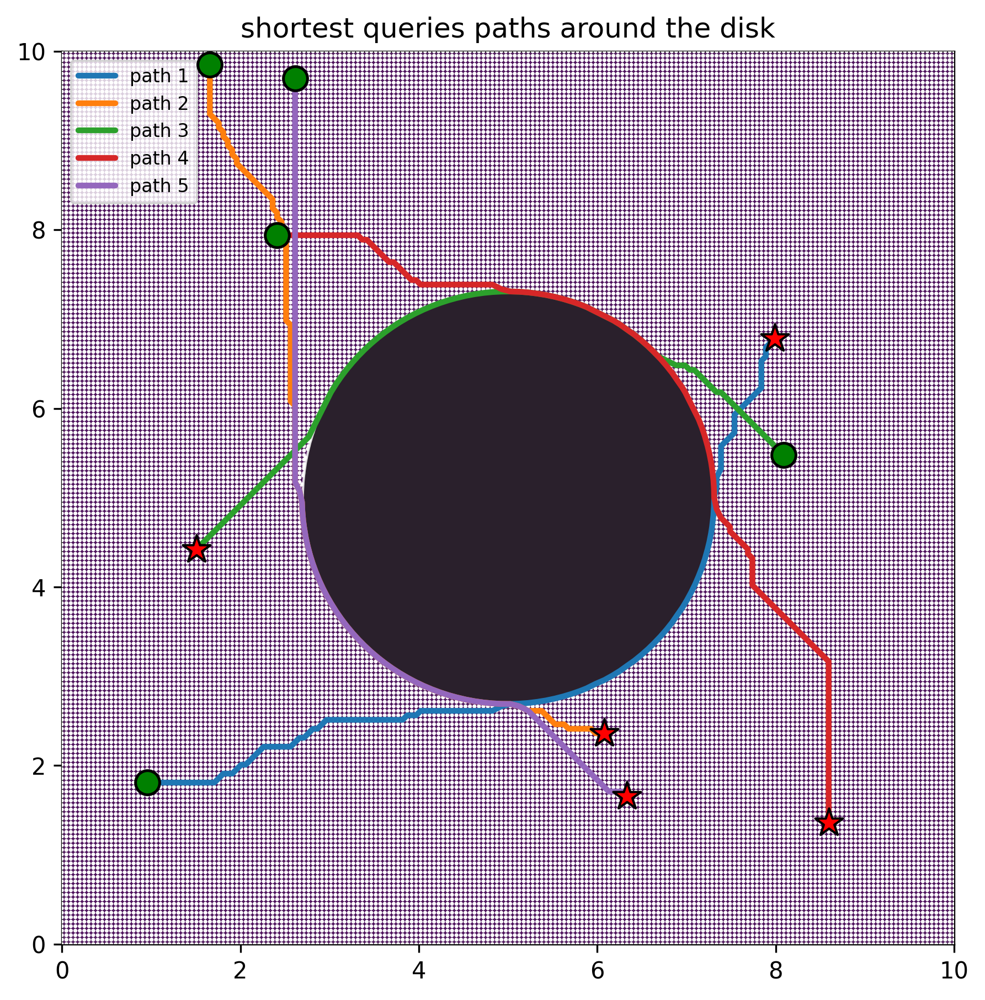

In [15]:
index = MultiH2HIndex(adj_uni_bound)
nearest_points = [nearest_node(points_uni_bound, p) for p in query_points]
strongle_affected_points = [ij for ij in affected_points if exact_dist[ij] > 1.1 * np.linalg.norm(query_points[ij[0]] - query_points[ij[1]])]
selected_points = [strongle_affected_points[k] for k in np.random.default_rng(0).choice(len(strongle_affected_points), size=5, replace=False)]

fig, ax = plt.subplots(figsize=(7, 7))
vz.plot_background(ax, manifold, bounds)
vz.plot_obstacles(ax, obstacles)
vz.plot_graph(ax, points_uni_bound, adj_uni_bound, node_size=3, edge_alpha=0.08)
colors = plt.cm.tab10(np.linspace(0, 1, 10))

for k, (i, j) in enumerate(selected_points):
    dist, path = index.query_path(nearest_points[i], nearest_points[j])
    vz.plot_path(ax, points_uni_bound, path, color=colors[k], label=f"path {k + 1}")
    print(f"path {k + 1}: exact dist: {exact_dist[(i, j)]}, h2h dist: {dist}")
    
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_aspect("equal")
ax.set_title("shortest queries paths around the disk")
ax.legend(loc="upper left", fontsize=8)
plt.show()

In [16]:
mani = PoincareDisk(rmax=0.95)
bounds = (-0.9, 0.9, -0.9, 0.9)

n = 60
rng = np.random.default_rng(2)
query_points = []
while len(query_points) < n:
    p = rng.uniform(-0.85, 0.85, 2)
    if not blocked(p, obstacles) and manifold.in_domain(p):
        query_points.append(p)
query_points = np.array(query_points)
pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]
exact_dist = {(i, j): exact_around_disk(query_points[i], query_points[j], c, r) for i, j in pairs}

diff_field = ad.difficulty_field(mani, bounds, [], res=80, weights=(1.0, 0.0, 0.0))



## Edge Impact

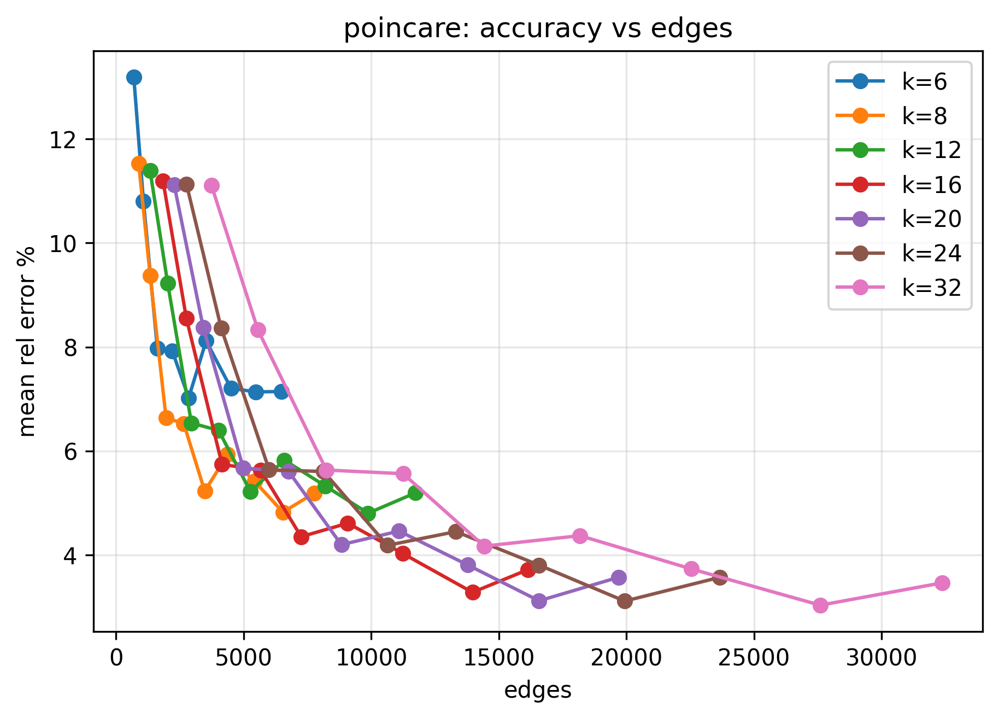

In [17]:
manifold = PoincareDisk(rmax=0.95)
bounds = (-0.9, 0.9, -0.9, 0.9)

n = 50
rng = np.random.default_rng(2) 
query_points = []
while len(query_points) < n:
    p = rng.uniform(-0.85, 0.85, 2)
    if manifold.in_domain(p):
        query_points.append(p)
query_points = np.array(query_points)
pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]
exact_dist = {(i, j): PoincareDisk.exact_dist(query_points[i], query_points[j]) for i, j in pairs}

def graph_error(points, adj):
    index = MultiH2HIndex(adj)
    nearest_points = [nearest_node(points, p) for p in query_points]
    rel_err = [abs(index.query(nearest_points[i], nearest_points[j]) - exact_dist[(i, j)]) / exact_dist[(i, j)] for (i, j) in pairs if index.same_component(nearest_points[i], nearest_points[j])]
    return np.array(rel_err)

fig, ax = plt.subplots(figsize=(7, 4.6))
for k in (6, 8, 12, 16, 20, 24, 32):
    edges, err = [], []
    for l in (16, 20, 24, 28, 32, 36, 40, 44, 48):
        points, adj = ad.build_uniform_graph(manifold, bounds, l, l, [], k=k)
        edges.append(sum(len(a) for a in adj) // 2)
        err.append(graph_error(points, adj).mean() * 100)
    ax.plot(edges, err, "o-", label=f"k={k}")
    
ax.set_xlabel("edges")
ax.set_ylabel("mean rel error %")
ax.set_title("poincare: accuracy vs edges")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## Manifold decomposition

8388 nodes, 689 separators, 16 portals each


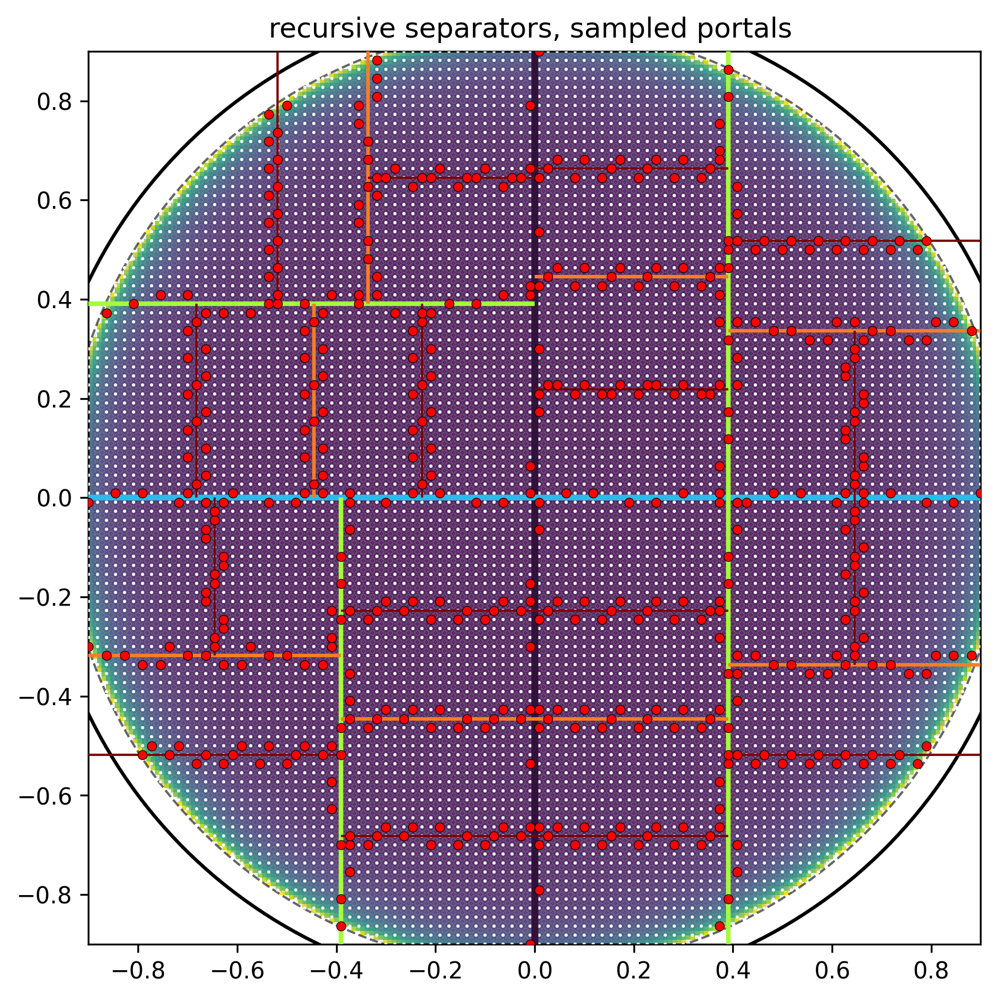

In [18]:
manifold = PoincareDisk(rmax=0.95)
bounds = (-0.9, 0.9, -0.9, 0.9)
points, adj = build_graph(manifold, bounds, 100, 100, [])
h2h = H2HIndex(adj)
SepIdx = SeparatorIndex(points, adj, k=16, leaf_size=16)
print(f"{len(points)} nodes, {SepIdx.num_seps} separators, {SepIdx.max_portals} portals each")

fig, ax = plt.subplots(figsize=(7, 7))
vz.plot_background(ax, manifold, bounds, res=200)
vz.plot_graph(ax, points, adj, node_size=2, edge_alpha=0.25)
vz.plot_separators(ax, SepIdx, max_depth=4)
ax.set_xlim(bounds[0], bounds[1])
ax.set_ylim(bounds[2], bounds[3])
ax.set_aspect("equal")
ax.set_title("recursive separators, sampled portals ")
plt.show()

separator d = 6.060815062132142
exact d = 6.059240263879476
rel error = 0.000259900281897404


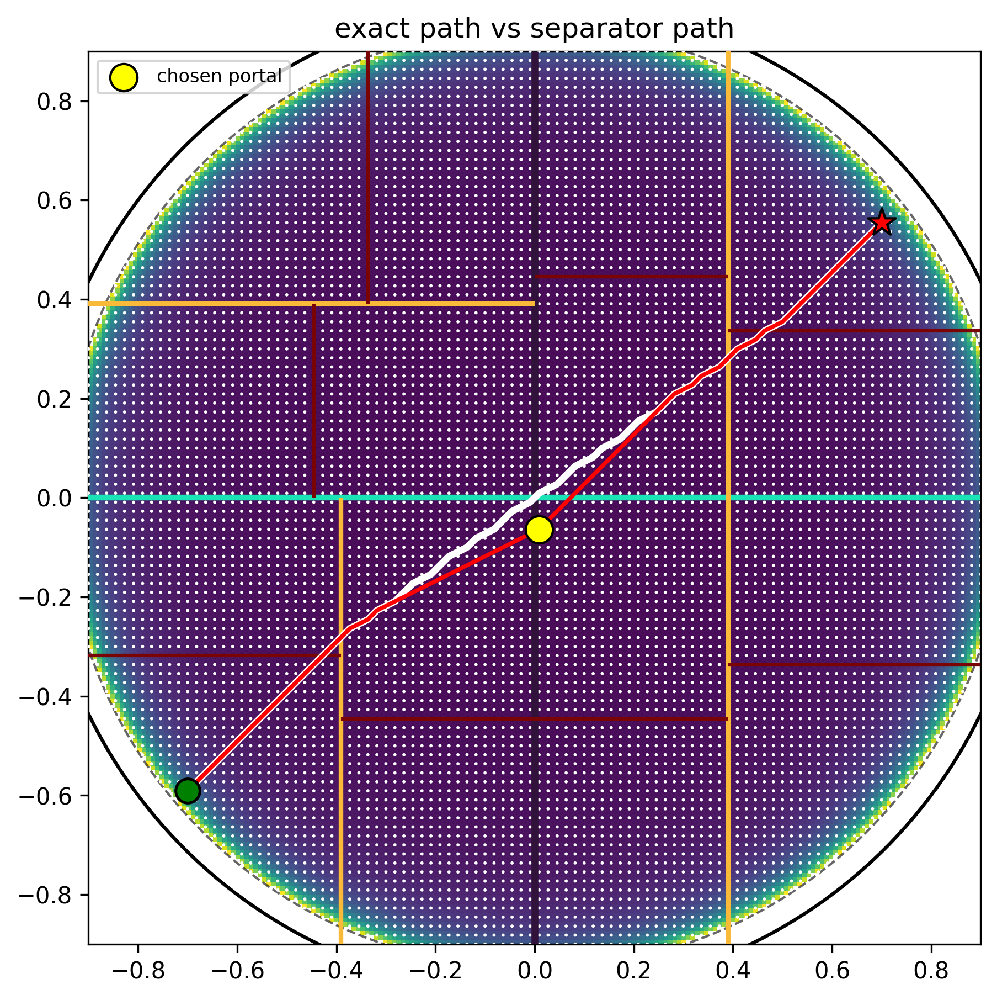

In [19]:
def nearest_node(points, xy):
    return int(np.argmin(np.sum((points - np.asarray(xy, float)) ** 2, axis=1)))

s = nearest_node(points, (-0.7, -0.6))
t = nearest_node(points, (0.7, 0.55))
d_sep, path_sep = SepIdx.query_path(s, t)
d_exact, path_exact = h2h.query_path(s, t)
sep = SepIdx.lcs(s, t)
tot = SepIdx.label[s][sep] + SepIdx.label[t][sep]
p = int(SepIdx.sep_portals[sep][int(tot.argmin())])
print(f"separator d = {d_sep}")
print(f"exact d = {d_exact}")
print(f"rel error = {(d_sep - d_exact) / d_exact}")

fig, ax = plt.subplots(figsize=(7, 7))
vz.plot_background(ax, mani, bounds, res=200)
vz.plot_graph(ax, points, adj, node_size=2, edge_alpha=0.05)
vz.plot_separators(ax, SepIdx, max_depth=3, show_portals=False)
vz.plot_path(ax, points, path_exact, color="white", lw=3.0, marker_ends=False)
vz.plot_path(ax, points, path_sep, color="red", lw=1.8)
ax.scatter([points[p][0]], [points[p][1]], s=140, c="yellow", edgecolors="black", zorder=8, label="chosen portal")
ax.set_xlim(bounds[0], bounds[1]); ax.set_ylim(bounds[2], bounds[3]); ax.set_aspect("equal")
ax.set_title("exact path vs separator path")
ax.legend(loc="upper left", fontsize=8)
plt.show()

k=4: build 237.4842444169335, query 6.538999965414405e-06, mean 7.113276707410525
k=8: build 324.66422291705385, query 6.372062489390373e-06, mean 1.6490726650611258
k=16: build 363.486080667004, query 7.621562574058771e-06, mean 0.4103955734512387
k=32: build 374.3129314999096, query 8.559187408536673e-06, mean 0.1316741490740098
k=64: build 370.86742408387363, query 1.0389895411208272e-05, mean 0.03430754377635419
h2h: build 37.70910920784809, query 9.723000111989677e-06


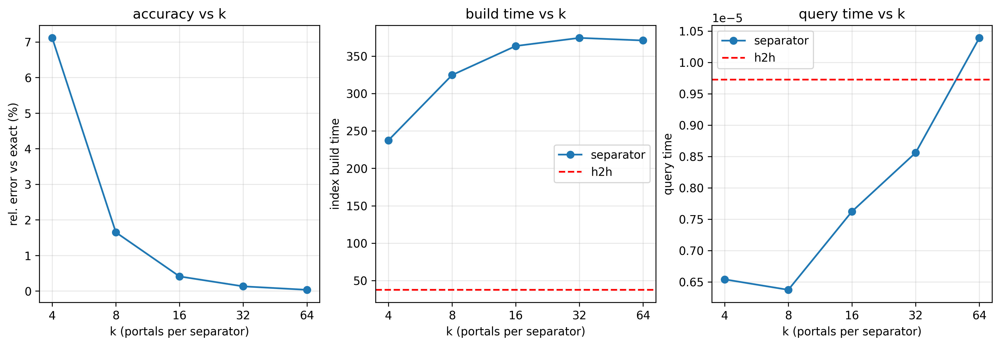

In [20]:
def query_time(fn):
    t0 = time.perf_counter()
    for s, t in qp:
        fn(s, t)
    return (time.perf_counter() - t0) / len(qp)

rng = np.random.default_rng(3)
n = len(points)
qp = [(int(rng.integers(n)), int(rng.integers(n))) for _ in range(2000)]
ks = [4, 8, 16, 32, 64]

t0 = time.perf_counter()
h2h = H2HIndex(adj)
h2h_build = time.perf_counter() - t0
h2h_query = query_time(h2h.query)

sep_build, sep_query, sep_mean = [], [], []
for k in ks:
    t0 = time.perf_counter()
    ix = SeparatorIndex(points, adj, k=k, leaf_size=8)
    sep_build.append(time.perf_counter() - t0)
    sep_query.append(query_time(ix.query))
    e = np.array([(ix.query(s, t) - h2h.query(s, t)) / h2h.query(s, t)
                  for s, t in qp if s != t and h2h.query(s, t) > 0]) * 100
    sep_mean.append(e.mean())
    print(f"k={k}: build {sep_build[-1]}, query {sep_query[-1]}, mean {sep_mean[-1]}")

print(f"h2h: build {h2h_build}, query {h2h_query}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
axes[0].plot(ks, sep_mean, "o-")
axes[0].set_xscale("log", base=2)
axes[0].set_xticks(ks)
axes[0].set_xticklabels(ks)
axes[0].set_xlabel("k (portals per separator)")
axes[0].set_ylabel("rel. error vs exact (%)")
axes[0].set_title("accuracy vs k")
axes[0].grid(alpha=0.3)

axes[1].plot(ks, sep_build, "o-", label="separator")
axes[1].axhline(h2h_build, color="red", ls="--", label="h2h")
axes[1].set_xscale("log", base=2)
axes[1].set_xticks(ks)
axes[1].set_xticklabels(ks)
axes[1].set_xlabel("k (portals per separator)")
axes[1].set_ylabel("index build time")
axes[1].set_title("build time vs k")
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(ks, sep_query, "o-", label="separator")
axes[2].axhline(h2h_query, color="red", ls="--", label="h2h")
axes[2].set_xscale("log", base=2)
axes[2].set_xticks(ks)
axes[2].set_xticklabels(ks)
axes[2].set_xlabel("k (portals per separator)")
axes[2].set_ylabel("query time")
axes[2].set_title("query time vs k")
axes[2].legend()
axes[2].grid(alpha=0.3)
plt.show()

dijkstra k=4: mean 0.08023593651392798, median 0.027155349165272184, build 3.1843942920677364, query 3.1708033032408927
dijkstra k=8: mean 0.03666448147099979, median 0.01465742684865968, build 0.6863414999097586, query 3.151370001323484
dijkstra k=16: mean 0.014590506203044775, median 0.010387252149925362, build 0.9438190408982337, query 3.187521570992685
dijkstra k=32: mean 0.01010592291391896, median 0.008866612602987153, build 1.1032788751181215, query 3.864760291104092
dijkstra k=64: mean 0.009192173162515738, median 0.008422830888329853, build 1.1524280831217766, query 3.193455366202917
continuous k=4: mean 0.08023593651392798, median 0.027155349165272184, build 0.5466233750339597, query 6.428159354861784
continuous k=8: mean 0.03666448147099979, median 0.01465742684865968, build 0.6811410000082105, query 6.066909650249133
continuous k=16: mean 0.014590506203044775, median 0.010387252149925362, build 0.9316924170125276, query 6.194124390616819
continuous k=32: mean 0.010105922913

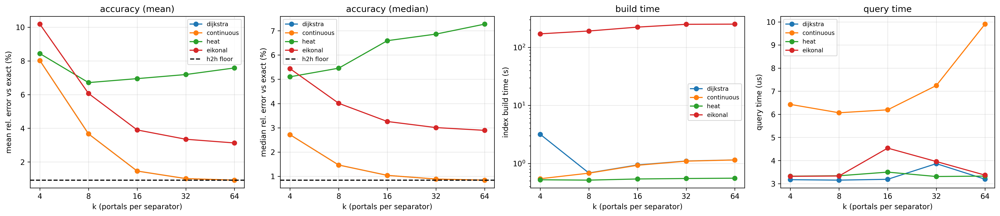

481 nodes, leaf_size=32, distinct portals per k: {4: 73, 8: 138, 16: 255, 32: 334, 64: 358}


In [21]:
mani = PoincareDisk(rmax=0.92)
bounds = (-0.9, 0.9, -0.9, 0.9)
points, adj = build_graph(mani, bounds, 25, 25, [])
n = len(points)
leaf_size = 32
ks = [4, 8, 16, 32, 64]

h2h = H2HIndex(adj)
rng = np.random.default_rng(3)
qp = [(int(rng.integers(n)), int(rng.integers(n))) for _ in range(1000)]
qp = [(s, t) for s, t in qp if s != t]
exact_dist = {(s, t): PoincareDisk.exact_dist(points[s], points[t]) for s, t in qp} #ground truth


def query_time(index):
    t0 = time.perf_counter()
    for s, t in qp:
        index.query(s, t)
    return (time.perf_counter() - t0) / len(qp)


def index_error(index):
    err = np.array([abs(index.query(s, t) - exact_dist[(s, t)]) / exact_dist[(s, t)] for s, t in qp])
    return err.mean(), np.median(err)


versions = {
    "dijkstra":   lambda k: SeparatorIndex(points, adj, k=k, leaf_size=leaf_size),
    "continuous": lambda k: SeparatorContinuousIndex(points, adj, k=k, leaf_size=leaf_size),
    "heat":       lambda k: SeparatorHeatIndex(points, adj, mani, k=k, leaf_size=leaf_size),
    "eikonal":    lambda k: SeparatorEikonalIndex(points, adj, mani, bounds, res=61, k=k, leaf_size=leaf_size),
}

res = {name: {"mean": [], "median": [], "build": [], "query": []} for name in versions}
for name, make in versions.items():
    for k in ks:
        t0 = time.perf_counter()
        index = make(k)
        build = time.perf_counter() - t0
        mean, median = index_error(index)
        res[name]["mean"].append(mean * 100)
        res[name]["median"].append(median * 100)
        res[name]["build"].append(build)
        res[name]["query"].append(query_time(index) * 1e6)
        print(f"{name} k={k}: mean {mean}, median {median}, build {build}, query {res[name]['query'][-1]}")

err_h2h = np.array([abs(h2h.query(s, t) - exact_dist[(s, t)]) / exact_dist[(s, t)] for s, t in qp])
portals = [len(np.unique(np.concatenate(SeparatorIndex(points, adj, k=k, leaf_size=leaf_size).sep_portals))) for k in ks]

fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
for name in versions:
    axes[0].plot(ks, res[name]["mean"], "o-", label=name)
    axes[1].plot(ks, res[name]["median"], "o-", label=name)
    axes[2].plot(ks, res[name]["build"], "o-", label=name)
    axes[3].plot(ks, res[name]["query"], "o-", label=name)

axes[0].axhline(err_h2h.mean() * 100, color="black", ls="--", label="h2h floor")
axes[1].axhline(np.median(err_h2h) * 100, color="black", ls="--", label="h2h floor")
axes[0].set_ylabel("mean rel. error vs exact (%)")
axes[0].set_title("accuracy (mean)")
axes[1].set_ylabel("median rel. error vs exact (%)")
axes[1].set_title("accuracy (median)")
axes[2].set_ylabel("index build time (s)")
axes[2].set_yscale("log")
axes[2].set_title("build time")
axes[3].set_ylabel("query time (us)")
axes[3].set_title("query time")

for a in axes:
    a.set_xscale("log", base=2)
    a.set_xticks(ks)
    a.set_xticklabels(ks)
    a.set_xlabel("k (portals per separator)")
    a.legend(fontsize=8)
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"{n} nodes, leaf_size={leaf_size}, distinct portals per k: {dict(zip(ks, portals))}")

### Pairs inside one leaf

In [22]:
manifold = PoincareDisk(rmax=0.92)
bounds = (-0.9, 0.9, -0.9, 0.9)
points, adj = build_graph(manifold, bounds, 25, 25, [])
n = len(points)

rng = np.random.default_rng(3)
qp = [(int(rng.integers(n)), int(rng.integers(n))) for _ in range(3000)]
qp = [(s, t) for s, t in qp if s != t]
exact_dist = {(s, t): PoincareDisk.exact_dist(points[s], points[t]) for s, t in qp}

for flag in (False, True):
    index = SeparatorIndex(points, adj, k=32, leaf_size=32, leaf_table=flag)
    same, diff = [], []
    for s, t in qp:
        e = abs(index.query(s, t) - exact_dist[(s, t)]) / exact_dist[(s, t)]
        (same if index.leaf_of[s] == index.leaf_of[t] else diff).append(e)
    same, diff = np.array(same), np.array(diff)
    both = np.concatenate([same, diff])
    print(f"leaf_table={flag}: overall {both.mean()}, same leaf {same.mean()} ({len(same)} pairs), diff leaf {diff.mean()}")

leaf_table=False: overall 0.037586960026126826, same leaf 0.5619993125280325 (148 pairs), diff leaf 0.010306458033057565
leaf_table=True: overall 0.010116569154474698, same leaf 0.006466340373608142 (148 pairs), diff leaf 0.010306458033057565


## Error analysis

$E = E_{quad} + E_{curve} + E_{metr}$

$E_{quad}$ - error from approximation a path

$E_{curve}$ - error from using some path and not minimizing geodesics between 2 nodes

$E_{metr}$ - error from discretizing

In [23]:
mani = PoincareDisk(rmax=0.95)
bounds = (-0.95, 0.95, -0.95, 0.95)
points, adj = build_graph(mani, bounds, 100, 100, [])
n = len(points)
adj_exact = [dict() for _ in range(n)]

for v in range(n):
    for u in adj[v]:
        adj_exact[v][u] = PoincareDisk.exact_dist(points[v], points[u])

idx = H2HIndex(adj)
idx_exact = H2HIndex(adj_exact)
rng = np.random.default_rng(1)
e_std, e_exact = [], []

while len(e_std) < 500:
    s, t = int(rng.integers(n)), int(rng.integers(n))
    if s == t:
        continue
    d = PoincareDisk.exact_dist(points[s], points[t])
    e_std.append(abs(idx.query(s, t) - d) / d)
    e_exact.append(abs(idx_exact.query(s, t) - d) / d)
    
e_std = np.array(e_std)
e_exact = np.array(e_exact)
print(f"segment_lenght weights: mean {e_std.mean()}, max {e_std.max()}")
print(f"exact weights: mean {e_exact.mean()}, max {e_exact.max()}")

segment_lenght weights: mean 0.00879907534118072, max 0.027400379907156717
exact weights: mean 0.008737959392848837, max 0.027393069829607895


so we see that having exact distance beetween points does not help, and the main error comes from graph structure $E_{quad}\approx 0, E_{curve} \approx 0$, so in this case the most error comes from discretizing

### The floor is set by the stencil, not by the node count

In [24]:
def stencil_gap(points, adj):
    P = np.asarray(points)
    angles = [np.arctan2(*(P[u] - P[v])[::-1]) % np.pi for v in range(len(adj)) for u in adj[v] if u > v]
    angles = np.unique(np.round(angles, 5))
    return angles, np.diff(np.concatenate([angles, [angles[0] + np.pi]])).max()


manifold = PoincareDisk(rmax=0.95)
bounds = (-0.95, 0.95, -0.95, 0.95)

for label, kind in [("rectangle", "rectangle"), ("triangular", "triangular")]:
    points, adj = build_graph(manifold, bounds, 60, 60, [], type=kind)
    angles, gap = stencil_gap(points, adj)
    bound = 1.0 / np.cos(gap / 2) - 1.0
    idx = H2HIndex(adj)
    n = len(points)
    rng = np.random.default_rng(1)
    err = []
    while len(err) < 800:
        s, t = int(rng.integers(n)), int(rng.integers(n))
        if s == t:
            continue
        d = PoincareDisk.exact_dist(points[s], points[t])
        err.append(abs(idx.query(s, t) - d) / d)
    err = np.array(err)
    print(f"{label}: {len(angles)} directions, max gap {np.degrees(gap)} deg")
    print(f"   predicted max sec(gap/2)-1 = {bound}, measured max {err.max()}, mean {err.mean()}")

rectangle: 8 directions, max gap 26.56518817124062 deg
   predicted max sec(gap/2)-1 = 0.02748658672316351, measured max 0.02737670244098545, mean 0.008948954630629672
triangular: 3 directions, max gap 63.435174327404795 deg
   predicted max sec(gap/2)-1 = 0.17557193435044116, measured max 0.17387367330705464, mean 0.07669746540949798


### More nodes do not help


graph R=20 (300 nodes): mean 0.009924045027542395, max 0.04355800961403932
graph R=30 (688 nodes): mean 0.008968475073259546, max 0.042656518272487086
graph R=40 (1256 nodes): mean 0.009306764640737784, max 0.02672295749801221
graph R=55 (2393 nodes): mean 0.008863042765164418, max 0.027343157722893877
eikonal res=61: mean 0.02644154171269517
eikonal res=121: mean 0.013874886804082442
eikonal res=181: mean 0.00957039682377337


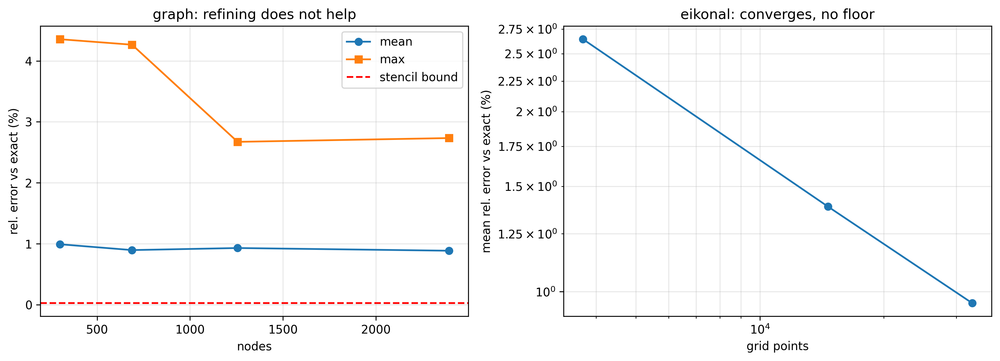

In [25]:
manifold = PoincareDisk(rmax=0.92)
bounds = (-0.9, 0.9, -0.9, 0.9)

grid_res, graph_mean, graph_max, nodes = [20, 30, 40, 55], [], [], []
for R in grid_res:
    points, adj = build_graph(manifold, bounds, R, R, [])
    idx = H2HIndex(adj)
    n = len(points)
    rng = np.random.default_rng(1)
    err = []
    while len(err) < 400:
        s, t = int(rng.integers(n)), int(rng.integers(n))
        if s == t:
            continue
        d = PoincareDisk.exact_dist(points[s], points[t])
        err.append(abs(idx.query(s, t) - d) / d)
    err = np.array(err)
    nodes.append(n)
    graph_mean.append(err.mean() * 100)
    graph_max.append(err.max() * 100)
    print(f"graph R={R} ({n} nodes): mean {err.mean()}, max {err.max()}")

src = (0.0, 0.0)
rng = np.random.default_rng(2)
probes = [p for p in rng.uniform(-0.8, 0.8, (40, 2)) if manifold.in_domain(p)]
eik_res, eik_mean = [61, 121, 181], []
for res in eik_res:
    xs, ys, u = solve_eikonal(manifold, bounds, res, res, [src])
    err = [abs(sample_field(xs, ys, u, p) - PoincareDisk.exact_dist(src, p)) / PoincareDisk.exact_dist(src, p) for p in probes]
    eik_mean.append(np.mean(err) * 100)
    print(f"eikonal res={res}: mean {np.mean(err)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].plot(nodes, graph_mean, "o-", label="mean")
axes[0].plot(nodes, graph_max, "s-", label="max")
axes[0].axhline(1.0 / np.cos(np.radians(26.565) / 2) - 1.0, color="red", ls="--", label="stencil bound")
axes[0].set_xlabel("nodes")
axes[0].set_ylabel("rel. error vs exact (%)")
axes[0].set_title("graph: refining does not help")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot([r * r for r in eik_res], eik_mean, "o-")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("grid points")
axes[1].set_ylabel("mean rel. error vs exact (%)")
axes[1].set_title("eikonal: converges, no floor")
axes[1].grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

In [26]:
manifold = PoincareDisk(rmax=0.95)
p, q = np.array([0.7, 0.1]), np.array([0.1, 0.7])
exact = PoincareDisk.exact_dist(p, q)
print(f"exact d = {exact}")

for n in (2, 4, 8, 16, 32):
    L = manifold.segment_lenght(p, q, n=n)
    print(f"  quadrature n={n}: {L}, err {(L - exact) / exact}")

for m in (1, 2, 4, 8, 16):
    pts = manifold.geodesic_path(p, q, m=m)
    L = sum(manifold.segment_lenght(pts[i], pts[i + 1], n=2) for i in range(len(pts) - 1))
    print(f"  path m={m}: {L}, err {(L - exact) / exact}")

exact d = 2.5986538764414044
  quadrature n=2: 2.7371875400769574, err 0.05330977891725269
  quadrature n=4: 2.759069063412282, err 0.06173010897109157
  quadrature n=8: 2.7592060421100455, err 0.061782820376410086
  quadrature n=16: 2.759206047005088, err 0.06178282226009403
  quadrature n=32: 2.7592060470050885, err 0.061782822260094204
  path m=1: 2.7371875400769574, err 0.05330977891725269
  path m=2: 2.626237402811568, err 0.010614544176208737
  path m=4: 2.605636846847715, err 0.002687149092696085
  path m=8: 2.6004284371022894, err 0.0006828768836714325
  path m=16: 2.5990994450171914, err 0.0001714613014939438


## Post Processing

h2h: raw 0.009283355644341833, refined 3.7030499898837e-05, refine 43.286448542200844 ms
separator k=8: raw 0.022795692964310582, refined 3.605487682801458e-05, refine 44.12523881892259 ms
separator k=16: raw 0.012181384036427543, refined 3.6605362569147177e-05, refine 44.094768566071615 ms
separator k=32: raw 0.010837353572149688, refined 3.7183210836089946e-05, refine 43.53914110913497 ms


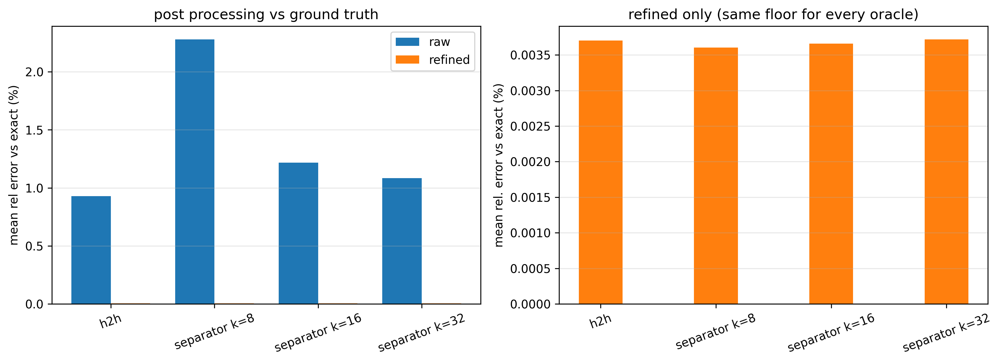

In [27]:
mani = PoincareDisk(rmax=0.92)
bounds = (-0.9, 0.9, -0.9, 0.9)
points, adj = build_graph(mani, bounds, 25, 25, [])
n = len(points)

rng = np.random.default_rng(7)
qp = [(int(rng.integers(n)), int(rng.integers(n))) for _ in range(120)]
qp = [(s, t) for s, t in qp if s != t]
exact_dist = {(s, t): PoincareDisk.exact_dist(points[s], points[t]) for s, t in qp}


def test_refine(index):
    raw, ref, times = [], [], []
    for s, t in qp:
        d, path = index.query_path(s, t)
        raw.append(abs(d - exact_dist[(s, t)]) / exact_dist[(s, t)])
        t0 = time.perf_counter()
        dr, coords = refine_path(mani, points, path)
        times.append(time.perf_counter() - t0)
        ref.append(abs(dr - exact_dist[(s, t)]) / exact_dist[(s, t)])
    return np.array(raw), np.array(ref), np.mean(times)


versions = [
    ("h2h", H2HIndex(adj)),
    ("separator k=8", SeparatorIndex(points, adj, k=8, leaf_size=32)),
    ("separator k=16", SeparatorIndex(points, adj, k=16, leaf_size=32)),
    ("separator k=32", SeparatorIndex(points, adj, k=32, leaf_size=32)),
]

names, raws, refs, secs = [], [], [], []
for name, index in versions:
    raw, ref, sec = test_refine(index)
    names.append(name)
    raws.append(raw.mean() * 100)
    refs.append(ref.mean() * 100)
    secs.append(sec * 1e3)
    print(f"{name}: raw {raw.mean()}, refined {ref.mean()}, refine {sec * 1e3} ms")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
x = np.arange(len(names))
w = 0.38
axes[0].bar(x - w / 2, raws, w, label="raw")
axes[0].bar(x + w / 2, refs, w, label="refined")
axes[0].set_xticks(x)
axes[0].set_xticklabels(names, rotation=20)
axes[0].set_ylabel("mean rel error vs exact (%)")
axes[0].set_title("post processing vs ground truth")
axes[0].legend()
axes[0].grid(alpha=0.3, axis="y")

axes[1].bar(x, refs, w, color="tab:orange")
axes[1].set_xticks(x)
axes[1].set_xticklabels(names, rotation=20)
axes[1].set_ylabel("mean rel. error vs exact (%)")
axes[1].set_title("refined only (same floor for every oracle)")
axes[1].grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

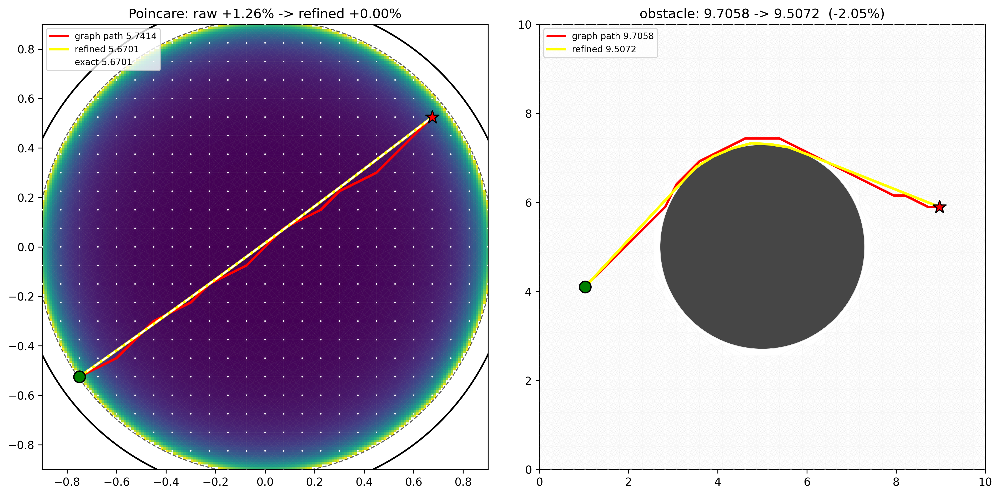

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))

mani = PoincareDisk(rmax=0.92)
bounds = (-0.9, 0.9, -0.9, 0.9)
points, adj = build_graph(mani, bounds, 25, 25, [])
idx = H2HIndex(adj)
s = nearest_node(points, (-0.72, -0.55))
t = nearest_node(points, (0.7, 0.5))
d_raw, path = idx.query_path(s, t)
d_ref, coords = refine_path(mani, points, path)
d_exact = PoincareDisk.exact_dist(points[s], points[t])

vz.plot_background(axes[0], mani, bounds, res=180)
vz.plot_graph(axes[0], points, adj, node_size=2, edge_alpha=0.07)
vz.plot_path(axes[0], points, path, color="red", lw=2.2, label=f"graph path {d_raw:.4f}")
vz.plot_polyline(axes[0], coords, color="yellow", lw=2.4, ls="-", label=f"refined {d_ref:.4f}")
vz.plot_polyline(axes[0], mani.exact_geodesic(points[s], points[t], 120), color="white", ls="--", lw=1.6, label=f"exact {d_exact:.4f}")
axes[0].set_title(f"Poincare: raw {(d_raw - d_exact) / d_exact:+.2%} -> refined {(d_ref - d_exact) / d_exact:+.2%}")
axes[0].set_xlim(bounds[0], bounds[1])
axes[0].set_ylim(bounds[2], bounds[3])

mani2 = Euclidean()
bounds2 = (0, 10, 0, 10)
obs = [Circle(5.0, 5.0, 2.3)]
pts2, adj2 = build_graph(mani2, bounds2, 40, 40, obs)
idx2 = H2HIndex(adj2)
s2 = nearest_node(pts2, (1.0, 4.2))
t2 = nearest_node(pts2, (9.0, 5.8))
d_raw2, path2 = idx2.query_path(s2, t2)
d_ref2, coords2 = refine_path(mani2, pts2, path2, obs)

vz.plot_obstacles(axes[1], obs)
vz.plot_graph(axes[1], pts2, adj2, node_size=2, edge_alpha=0.07)
vz.plot_path(axes[1], pts2, path2, color="red", lw=2.2, label=f"graph path {d_raw2:.4f}")
vz.plot_polyline(axes[1], coords2, color="yellow", lw=2.4, ls="-", label=f"refined {d_ref2:.4f}")
axes[1].set_title(f"obstacle: {d_raw2:.4f} -> {d_ref2:.4f}  ({(d_ref2 - d_raw2) / d_raw2:+.2%})")
axes[1].set_xlim(0, 10)
axes[1].set_ylim(0, 10)

for a in axes:
    a.set_aspect("equal")
    a.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [29]:
hills = [(3.0, 3.0, 2.2, 0.6), (7.0, 6.5, 2.5, 0.7), (5.0, 8.0, 1.8, 0.5)]
setups = [("GaussianHills", GaussianHills(hills), (0, 10, 0, 10), 30),
          ("Terrain", Terrain(amp=0.9, freq=1.2), (0, 7, 0, 7), 30)]
res = 251
L = 12

for name, mani, bounds, grid in setups:
    print(f"=== {name}  (anisotropy {anisotropy_ratio(mani, bounds, res=40)}) ===")
    points, adj = build_graph(mani, bounds, grid, grid, [])
    n = len(points)
    h2h = H2HIndex(adj)
    sep = SeparatorIndex(points, adj, k=16, leaf_size=16)

    rng = np.random.default_rng(5)
    x0, x1, y0, y1 = bounds
    lm = []
    while len(lm) < L:
        p = rng.uniform([x0 + 0.05 * (x1 - x0), y0 + 0.05 * (y1 - y0)],
                        [x1 - 0.05 * (x1 - x0), y1 - 0.05 * (y1 - y0)])
        if mani.in_domain(p):
            lm.append(nearest_node(points, p))
    lm = list(dict.fromkeys(lm))

    field = {}
    for i in lm: #eikonal converges to the true distance, the graph does not
        field[i] = solve_eikonal(mani, bounds, res, res, [points[i]])

    pairs = [(i, j) for a, i in enumerate(lm) for j in lm[a + 1:]]
    truth = {}
    for i, j in pairs:
        xs, ys, u = field[i]
        truth[(i, j)] = sample_field(xs, ys, u, points[j])

    for label, kind in [("h2h raw", None), ("separator raw", None),
                        ("h2h + shortcut", dict(use_relax=False)), ("h2h + full refine", dict())]:
        idx = sep if "separator" in label else h2h
        errs, below = [], 0
        for i, j in pairs:
            ex = truth[(i, j)]
            if not np.isfinite(ex) or ex <= 0:
                continue
            if kind is None:
                d = idx.query(i, j)
            else:
                _, path = idx.query_path(i, j)
                d, _ = refine_path(mani, points, path, **kind)
            errs.append((d - ex) / ex)
            if d < ex:
                below += 1
        e = np.array(errs)
        print(f"  {label}: signed mean {e.mean()}, abs {np.abs(e).mean()}, below truth {below}/{len(e)}")

=== GaussianHills  (anisotropy 2.438272349390233) ===
  h2h raw: signed mean 0.009243788694963352, abs 0.011532241432528238, below truth 8/66
  separator raw: signed mean 0.01173267333992241, abs 0.013277211359908486, below truth 4/66
  h2h + shortcut: signed mean -0.0030054695326166337, abs 0.00790794794280533, below truth 32/66
  h2h + full refine: signed mean -0.003441727764701186, abs 0.004393096331430221, below truth 51/66
=== Terrain  (anisotropy 1.471869559437928) ===
  h2h raw: signed mean 0.007339604842869693, abs 0.00957722305402552, below truth 9/66
  separator raw: signed mean 0.009986133241124214, abs 0.011916439743523265, below truth 6/66
  h2h + shortcut: signed mean 0.0007564787679728085, abs 0.008612276073553636, below truth 22/66
  h2h + full refine: signed mean -0.003191879207727656, abs 0.00444355624039317, below truth 54/66


dijkstra (no index): build 4.169996827840805e-07, query 1639.5193751668558us, err 0.9159624101473238%
h2h: build 0.4446456669829786, query 6.595312152057886us, err 0.915962410147322%
sep heat k=16: build 0.5906756250187755, query 4.33687528129667us, err 6.705983679376387%
sep k=4: build 0.9810497500002384, query 4.092499730177224us, err 9.052784224894834%
sep k=8: build 1.5781240419019014, query 4.07364743296057us, err 2.6443118370113985%
sep k=16: build 2.0498610839713365, query 4.0715624345466495us, err 1.0752766873839914%
sep k=32: build 2.268004500074312, query 3.9302097866311674us, err 0.9583443789457672%
sep k=64: build 2.3151107081212103, query 4.0435424307361245us, err 0.9159624101473215%
sep k=4 refined labels: build 18.32153679197654, query 5.312915309332311us, err 8.508175954455723%
sep k=8 refined labels: build 32.82207916607149, query 4.103437531739473us, err 2.1210895025571004%
sep k=16 refined labels: build 60.16661554109305, query 5.2873947424814105us, err 0.53253028016

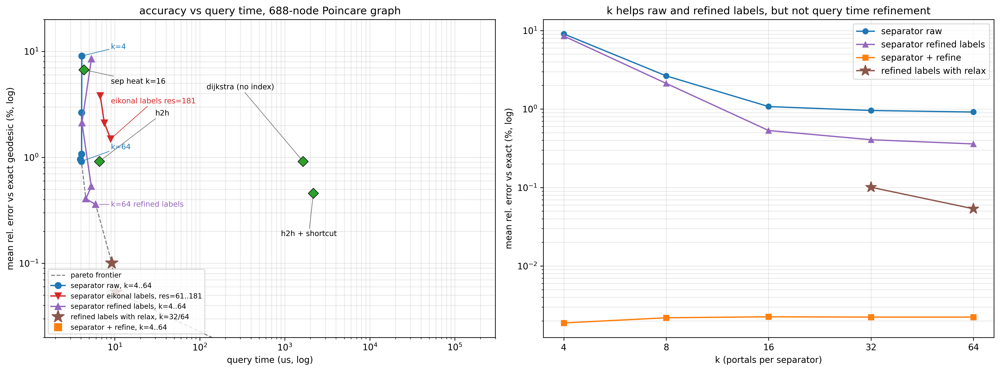

In [ ]:
mani = PoincareDisk(rmax=0.92)
bounds = (-0.9, 0.9, -0.9, 0.9)
points, adj = build_graph(mani, bounds, 30, 30, [])
n = len(points)

rng = np.random.default_rng(3)
qp = [(int(rng.integers(n)), int(rng.integers(n))) for _ in range(400)]
qp = [(s, t) for s, t in qp if s != t]
exact_dist = {(s, t): PoincareDisk.exact_dist(points[s], points[t]) for s, t in qp}
qp_small = qp[:40] #refinement is per query and slow, time it on a subset


def measure(name, build, query, sample):
    t0 = time.perf_counter()
    index = build()
    build_time = time.perf_counter() - t0
    pairs = qp_small if sample else qp
    errs, t0 = [], time.perf_counter()
    for s, t in pairs:
        errs.append(abs(query(index, s, t) - exact_dist[(s, t)]) / exact_dist[(s, t)])
    per_query = (time.perf_counter() - t0) / len(pairs)
    return dict(name=name, build=build_time, query=per_query * 1e6, err=np.mean(errs) * 100)


ks = [4, 8, 16, 32, 64]
h2h_only = lambda: H2HIndex(adj)
rows = [
    measure("dijkstra (no index)", lambda: None, lambda ix, s, t: dijkstra(adj, s, t)[0][t], False),
    measure("h2h", h2h_only, lambda ix, s, t: ix.query(s, t), False),
    measure("sep heat k=16", lambda: SeparatorHeatIndex(points, adj, mani, k=16, leaf_size=16), lambda ix, s, t: ix.query(s, t), False),
]
for k in ks:
    rows.append(measure(f"sep k={k}", lambda k=k: SeparatorIndex(points, adj, k=k, leaf_size=16),
                        lambda ix, s, t: ix.query(s, t), False))
for k in ks:
    rows.append(measure(f"sep k={k} refined labels", lambda k=k: SeparatorRefinedIndex(points, adj, mani, k=k, leaf_size=16, use_relax=False),
                        lambda ix, s, t: ix.query(s, t), False))
heavy = True #the eikonal and full relax builds below are minutes, set False to skip them
eik_res = [61, 121, 181] if heavy else [61]
for res in eik_res: #k does not help eikonal labels, resolution does, so sweep that instead
    rows.append(measure(f"sep eikonal labels res={res}", lambda res=res: SeparatorEikonalIndex(points, adj, mani, bounds, res=res, leaf_res=res, k=16, leaf_size=16),
                        lambda ix, s, t: ix.query(s, t), False))
for k in ([32, 64] if heavy else []): #labels refined with relax, not just shortcut
    rows.append(measure(f"sep k={k} refined labels (relax)", lambda k=k: SeparatorRefinedIndex(points, adj, mani, k=k, leaf_size=16, use_relax=True),
                        lambda ix, s, t: ix.query(s, t), False))
for k in ks:
    rows.append(measure(f"sep k={k} + refine", lambda k=k: SeparatorIndex(points, adj, k=k, leaf_size=16),
                        lambda ix, s, t: refine_path(mani, points, ix.query_path(s, t)[1])[0], True))
rows.append(measure("h2h + shortcut", h2h_only,
                    lambda ix, s, t: refine_path(mani, points, ix.query_path(s, t)[1], use_relax=False)[0], True))
rows.append(measure("h2h + full refine", h2h_only,
                    lambda ix, s, t: refine_path(mani, points, ix.query_path(s, t)[1])[0], True))

for r in rows:
    print(f"{r['name']}: build {r['build']}, query {r['query']}us, err {r['err']}%")

front = []
for r in sorted(rows, key=lambda r: r["query"]):
    if not front or r["err"] < front[-1]["err"]:
        front.append(r)
print("pareto frontier:", [r["name"] for r in front])

raw_k = [r["err"] for r in rows if r["name"].startswith("sep k=") and "refine" not in r["name"]]
ref_k = [r["err"] for r in rows if r["name"].startswith("sep k=") and "+ refine" in r["name"]]

by = {r["name"]: r for r in rows}
raw_k = [by[f"sep k={k}"] for k in ks]
ref_k = [by[f"sep k={k} + refine"] for k in ks]
lab_k = [by[f"sep k={k} refined labels"] for k in ks]
eik_k = [by[f"sep eikonal labels res={r}"] for r in eik_res]
rel_k = [by[f"sep k={k} refined labels (relax)"] for k in ([32, 64] if heavy else [])]

callouts = [("sep heat k=16", 9.0, 5.2), ("h2h", 30.0, 2.6), ("dijkstra (no index)", 120.0, 4.6), ("h2h + shortcut", 900.0, 0.19)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ax = axes[0]
ax.plot([r["query"] for r in front], [r["err"] for r in front], "--", color="0.5", lw=1.2, zorder=1, label="pareto frontier")
ax.plot([r["query"] for r in raw_k], [r["err"] for r in raw_k], "o-", color="tab:blue", ms=7, zorder=3, label="separator raw, k=4..64")
ax.plot([r["query"] for r in eik_k], [r["err"] for r in eik_k], "v-", color="tab:red", ms=7, zorder=3, label="separator eikonal labels, res=61..181")
ax.plot([r["query"] for r in lab_k], [r["err"] for r in lab_k], "^-", color="tab:purple", ms=7, zorder=3, label="separator refined labels, k=4..64")
if rel_k:
    ax.plot([r["query"] for r in rel_k], [r["err"] for r in rel_k], "*", color="tab:brown", ms=15, zorder=5, label="refined labels with relax, k=32/64")
ax.plot([r["query"] for r in ref_k], [r["err"] for r in ref_k], "s", color="tab:orange", ms=8, zorder=3, label="separator + refine, k=4..64")

for name in [c[0] for c in callouts] + ["h2h + full refine"]:
    r = by[name]
    ax.scatter(r["query"], r["err"], s=70, c="tab:green", marker="D", edgecolors="black", linewidths=0.6, zorder=4)
for name, lx, ly in callouts:
    r = by[name]
    ax.annotate(name, xy=(r["query"], r["err"]), xytext=(lx, ly), fontsize=8.5, ha="left", va="center",
                arrowprops=dict(arrowstyle="-", lw=0.7, color="0.45", shrinkA=0, shrinkB=4))
for r, lab, col, lx, ly in [(raw_k[0], "k=4", "tab:blue", 9.0, 11.0), (raw_k[-1], "k=64", "tab:blue", 9.0, 1.25),
                            (lab_k[-1], "k=64 refined labels", "tab:purple", 9.0, 0.36),
                            (eik_k[-1], f"eikonal labels res={eik_res[-1]}", "tab:red", 9.0, 3.4)]:
    ax.annotate(lab, xy=(r["query"], r["err"]), xytext=(lx, ly), fontsize=8.5, color=col, ha="left", va="center",
                arrowprops=dict(arrowstyle="-", lw=0.7, color=col, shrinkA=0, shrinkB=4))
ax.annotate("all refined collapse here\n(sep k=4..64 and h2h, ~0.034%)",
            xy=(ref_k[0]["query"], ref_k[0]["err"]), xytext=(150.0, 0.075), fontsize=8.5, ha="left", va="center",
            arrowprops=dict(arrowstyle="->", lw=0.8, color="0.3"))

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1.5, 3e5)
ax.set_ylim(0.02, 20)
ax.set_xlabel("query time (us, log)")
ax.set_ylabel("mean rel. error vs exact geodesic (%, log)")
ax.set_title(f"accuracy vs query time, {n}-node Poincare graph")
ax.grid(alpha=0.3, which="both")
ax.legend(loc="lower left", fontsize=8)

ax = axes[1]
ax.plot(ks, [r["err"] for r in raw_k], "o-", color="tab:blue", label="separator raw")
ax.plot(ks, [r["err"] for r in lab_k], "^-", color="tab:purple", label="separator refined labels")
ax.plot(ks, [r["err"] for r in ref_k], "s-", color="tab:orange", label="separator + refine")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks(ks)
ax.set_xticklabels(ks)
ax.set_xlabel("k (portals per separator)")
ax.set_ylabel("mean rel. error vs exact (%, log)")
ax.set_title("k helps raw and refined labels, but not query time refinement")
if rel_k:
    ax.plot([32, 64], [r["err"] for r in rel_k], "*-", color="tab:brown", ms=13, label="refined labels with relax")
    ax.legend()
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

### Portals per separator depending on the cut length

fixed k=6: portals 102, build 142.81910579209216, err 2.347640300116923, interp 2.4369028689712944
fixed k=9: portals 153, build 202.7448127081152, err 0.7962863808342435, interp 0.8516100106145743
fixed k=12: portals 204, build 289.77122787502594, err 0.538938191284612, interp 0.4783746479265173
fixed k=16: portals 272, build 349.67994479089975, err 0.27412022394040164, interp 0.23308082753330434
scale_k k=16: portals 173, build 252.61215800000355, err 0.3863591373145189, interp 0.4264965556358063
scale_k k=32: portals 341, build 478.4897906659171, err 0.1521379771251597, interp 0.12265440370533398
scale_k k=48: portals 516, build 698.1546441658866, err 0.09733566359583791, interp 0.07803739989414575


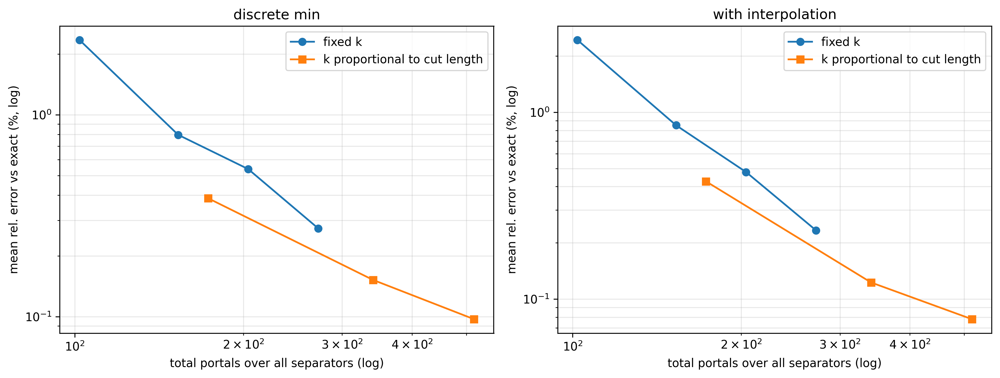

In [2]:
manifold = PoincareDisk(rmax=0.92)
bounds = (-0.9, 0.9, -0.9, 0.9)
points, adj = build_graph(manifold, bounds, 16, 16, [])
n = len(points)

rng = np.random.default_rng(3)
qp = [(int(rng.integers(n)), int(rng.integers(n))) for _ in range(2000)]
qp = [(s, t) for s, t in qp if s != t]
exact_dist = {(s, t): PoincareDisk.exact_dist(points[s], points[t]) for s, t in qp}


def run(**kw):
    t0 = time.perf_counter()
    index = SeparatorCutIndex(points, adj, manifold, leaf_size=16, alpha=0.0, interpolate=False, **kw)
    build = time.perf_counter() - t0
    portals = sum(len(p) for p in index.cut_pos)
    err = np.mean([abs(index.query(s, t) - exact_dist[(s, t)]) / exact_dist[(s, t)] for s, t in qp]) * 100
    index.interpolate = True
    interp = np.mean([abs(index.query(s, t) - exact_dist[(s, t)]) / exact_dist[(s, t)] for s, t in qp]) * 100
    return portals, build, err, interp


fixed, scaled = [], []
for k in (6, 9, 12, 16):
    fixed.append(run(k=k, scale_k=False))
    print(f"fixed k={k}: portals {fixed[-1][0]}, build {fixed[-1][1]}, err {fixed[-1][2]}, interp {fixed[-1][3]}")
for k in (16, 32, 48):
    scaled.append(run(k=k, scale_k=True))
    print(f"scale_k k={k}: portals {scaled[-1][0]}, build {scaled[-1][1]}, err {scaled[-1][2]}, interp {scaled[-1][3]}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].plot([r[0] for r in fixed], [r[2] for r in fixed], "o-", label="fixed k")
axes[0].plot([r[0] for r in scaled], [r[2] for r in scaled], "s-", label="k proportional to cut length")
axes[1].plot([r[0] for r in fixed], [r[3] for r in fixed], "o-", label="fixed k")
axes[1].plot([r[0] for r in scaled], [r[3] for r in scaled], "s-", label="k proportional to cut length")
for ax, title in [(axes[0], "discrete min"), (axes[1], "with interpolation")]:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("total portals over all separators (log)")
    ax.set_ylabel("mean rel. error vs exact (%, log)")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

## Сравнение всех вариантов индекса

Точность против времени запроса, и отдельно стоимость построения. Ground truth --- точная гиперболическая формула, поэтому ошибка меряется относительно настоящей геодезической, а не относительно графа.

Три семейства ведут себя по-разному. Сырые сепараторы дёшевы во всём, но упираются в пол графа. Refined и cut labels переносят стоимость в препроцессинг и уходят под этот пол. Refine на запросе даёт ещё два порядка, но платит миллисекундами за запрос.

Отдельно видно, где `k` ещё что-то покупает: у обычных порталов и refined labels портал --- это вершина графа возле разреза, и на 188 вершинах кандидатов меньше 32 на разрез, так что `k=64` не меняет ничего. У cut portals порталы ставятся на саму линию разреза, там `k` не ограничен графом и `k=64` честно вдвое точнее.


In [ ]:
manifold = PoincareDisk(rmax=0.92)
bounds = (-0.9, 0.9, -0.9, 0.9)
points, adj = build_graph(manifold, bounds, 16, 16, [])
n = len(points)

rng = np.random.default_rng(3)
qp = [(int(rng.integers(n)), int(rng.integers(n))) for _ in range(1500)]
qp = [(s, t) for s, t in qp if s != t]
exact_dist = {(s, t): PoincareDisk.exact_dist(points[s], points[t]) for s, t in qp}
qp_slow = qp[:60] #refine на запросе слишком медленный для полного набора

rows = []


def build_timed(make):
    t0 = time.perf_counter()
    index = make()
    return index, time.perf_counter() - t0


def measure(name, index, build_time, query, slow=False):
    pairs = qp_slow if slow else qp
    errs, t0 = [], time.perf_counter()
    for s, t in pairs:
        errs.append(abs(query(index, s, t) - exact_dist[(s, t)]) / exact_dist[(s, t)])
    per_query = (time.perf_counter() - t0) / len(pairs) * 1e6
    rows.append(dict(name=name, build=build_time, query=per_query, err=np.mean(errs) * 100))
    print(f"{name:32s} build {build_time:7.1f}s | query {per_query:9.2f}us | err {rows[-1]['err']:.4f}%")


lite = dict(rounds=1, use_relax=True, segments=12) #чтобы построение оставалось приемлемым
Q = lambda ix, s, t: ix.query(s, t)

measure("dijkstra (no index)", None, 0.0, lambda ix, s, t: dijkstra(adj, s, t)[0][t])
measure("h2h", *build_timed(lambda: H2HIndex(adj)), Q)
for k in (8, 32, 64):
    measure(f"separator portals k={k}",
            *build_timed(lambda k=k: SeparatorIndex(points, adj, k=k, leaf_size=16)), Q)
measure("separator BFS frontier k=32",
        *build_timed(lambda: SeparatorBFSRefinedIndex(points, adj, manifold, k=32, leaf_size=16, **lite)), Q)
for k in (32, 64):
    measure(f"refined labels k={k}",
            *build_timed(lambda k=k: SeparatorRefinedIndex(points, adj, manifold, k=k, leaf_size=16, **lite)), Q)
for k in (32, 64):
    #interpolate читается только на запросе, так что оба режима делят один индекс и одну стоимость сборки
    cut, bt = build_timed(lambda k=k: SeparatorCutIndex(points, adj, manifold, k=k, leaf_size=16, **lite))
    cut.interpolate = False
    measure(f"cut portals k={k} discrete", cut, bt, Q)
    cut.interpolate = True
    measure(f"cut portals k={k} interpolated", cut, bt, Q)

h2h_index, bt = build_timed(lambda: H2HIndex(adj))
measure("h2h + shortcut", h2h_index, bt,
        lambda ix, s, t: refine_path(manifold, points, ix.query_path(s, t)[1], use_relax=False)[0], slow=True)
measure("h2h + refine (rounds=1)", h2h_index, bt,
        lambda ix, s, t: refine_path(manifold, points, ix.query_path(s, t)[1], rounds=1, segments=20)[0], slow=True)
measure("h2h + refine (rounds=2)", h2h_index, bt,
        lambda ix, s, t: refine_path(manifold, points, ix.query_path(s, t)[1])[0], slow=True)

family = {"dijkstra (no index)": "baseline", "h2h": "baseline",
          "separator portals k=8": "raw separator", "separator portals k=32": "raw separator",
          "separator portals k=64": "raw separator", "separator BFS frontier k=32": "refined labels",
          "refined labels k=32": "refined labels", "refined labels k=64": "refined labels",
          "cut portals k=32 discrete": "cut portals", "cut portals k=32 interpolated": "cut portals",
          "cut portals k=64 discrete": "cut portals", "cut portals k=64 interpolated": "cut portals",
          "h2h + shortcut": "query-time refine", "h2h + refine (rounds=1)": "query-time refine",
          "h2h + refine (rounds=2)": "query-time refine"}
colour = {"baseline": "tab:gray", "raw separator": "tab:blue", "refined labels": "tab:purple",
          "cut portals": "tab:green", "query-time refine": "tab:orange"}
marker = {"baseline": "D", "raw separator": "o", "refined labels": "^", "cut portals": "s", "query-time refine": "*"}

front = [] #на фронте ничего нет одновременно быстрее и точнее
for r in sorted(rows, key=lambda r: r["query"]):
    if not front or r["err"] < front[-1]["err"]:
        front.append(r)
print("pareto:", [r["name"] for r in front])

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
ax = axes[0]
ax.plot([r["query"] for r in front], [r["err"] for r in front], "--", color="0.55", lw=1.2, zorder=1, label="pareto frontier")
seen = set()
for r in rows:
    f = family[r["name"]]
    ax.scatter(r["query"], r["err"], s=210 if marker[f] == "*" else 85, c=colour[f], marker=marker[f],
               edgecolors="black", lw=0.6, zorder=3, label=f if f not in seen else None)
    seen.add(f)
#k=32 и k=64 выбирают одни и те же порталы, поэтому у них одна общая подпись
place = {"separator portals k=8": (22, 6.0), "h2h": (22, 3.0),
         "separator portals k=32": None, "separator portals k=64": (22, 1.7),
         "separator BFS frontier k=32": (26, 0.50),
         "refined labels k=32": None, "refined labels k=64": (26, 0.26),
         "cut portals k=32 discrete": (26, 0.135), "cut portals k=32 interpolated": (60, 0.088),
         "cut portals k=64 discrete": (26, 0.045), "cut portals k=64 interpolated": (60, 0.029),
         "dijkstra (no index)": (900, 2.8), "h2h + shortcut": (2200, 0.9),
         "h2h + refine (rounds=1)": (1100, 0.0068), "h2h + refine (rounds=2)": (3500, 0.0023)}
text = {"separator portals k=64": "separator portals k=32, k=64 (identical)",
        "refined labels k=64": "refined labels k=32, k=64 (identical)"}
for r in rows:
    if place[r["name"]] is None:
        continue
    x, y = place[r["name"]]
    ax.annotate(text.get(r["name"], r["name"]), xy=(r["query"], r["err"]), xytext=(x, y),
                fontsize=8, ha="left", va="center",
                arrowprops=dict(arrowstyle="-", lw=0.7, color="0.45", shrinkA=0, shrinkB=5))
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(2.4, 2e5)
ax.set_ylim(0.002, 12)
ax.set_xlabel("query time (us, log)")
ax.set_ylabel("mean rel. error vs exact geodesic (%, log)")
ax.set_title(f"accuracy vs query time, {n}-node Poincare graph")
ax.grid(alpha=0.3, which="both")
ax.legend(loc="lower left", fontsize=8)

ax = axes[1]
order = sorted(rows, key=lambda r: r["build"])
ax.barh([r["name"] for r in order], [max(r["build"], 1e-3) for r in order],
        color=[colour[family[r["name"]]] for r in order], edgecolor="black", lw=0.5)
ax.set_xscale("log")
ax.set_xlabel("index build time (s, log)")
ax.set_title("build cost (one-off)")
ax.grid(alpha=0.3, axis="x", which="both")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

### Почему `k` перестаёт что-либо покупать

У обычных порталов и refined labels портал --- это вершина графа внутри полосы вокруг разреза.
`k` тут не квота, а потолок: если кандидатов меньше `k`, берутся все. Ниже видно, что на 188
вершинах ни один разрез не даёт больше 32 кандидатов, поэтому `k=64` ничего не меняет.

У cut portals порталы ставятся на саму линию, граф их не ограничивает, и `k=64` честно удваивает
их число.

In [ ]:
manifold = PoincareDisk(rmax=0.92)
points, adj = build_graph(manifold, (-0.9, 0.9, -0.9, 0.9), 16, 16, [])

seen = {}
original = SeparatorIndex.subsample


def spy(self, candidates, other_axis): #перехватываем отбор, чтобы увидеть число кандидатов
    seen.setdefault(self.k, []).append(len(candidates))
    return original(self, candidates, other_axis)


SeparatorIndex.subsample = spy
for k in (8, 32, 64):
    index = SeparatorIndex(points, adj, k=k, leaf_size=16)
    portals = [len(p) for p in index.sep_portals]
    print(f"вершинные порталы k={k:3d} | band {index.band:.4f} | кандидатов {sum(seen[k]):4d} "
          f"| порталов {sum(portals):4d} | max/разрез {max(portals):3d}")
SeparatorIndex.subsample = original
print("кандидатов на каждом разрезе:", seen[32])

for k in (32, 64):
    index = SeparatorCutIndex(points, adj, manifold, k=k, leaf_size=16, rounds=0, use_relax=False)
    on_cut = [len(p) for p in index.cut_xy]
    print(f"порталы на разрезе k={k:3d} | всего {sum(on_cut):4d} | max/разрез {max(on_cut):3d} "
          f"| в среднем {np.mean(on_cut):.1f}")

## Чем мерить, если замкнутой формулы нет

На диске Пуанкаре есть `exact_dist`. На GaussianHills её нет, и напрашивается взять dijkstra по
очень плотному графу. Так делать нельзя.

Графовый dijkstra сходится не к римановой метрике, а к финслеровой метрике шаблона: ошибка
задаётся угловым зазором между направлениями рёбер, а не шагом сетки. Значит она не падает с
разрешением. Первый цикл ниже это показывает, второй --- подтверждает причину, меняя число
соседей при фиксированном разрешении и сравнивая с $\sec(\theta_{\max}/2)-1$.

Вывод: reference должен сам уходить с графа --- плотный граф только за топологию, длину считает
`refine_polyline`.

In [ ]:
hills = [(3.0, 3.0, 2.2, 0.6), (7.0, 6.5, 2.5, 0.7), (5.0, 8.0, 1.8, 0.5)]
manifold = GaussianHills(hills)
bounds = (0, 10, 0, 10)
obstacles = [Circle(5.0, 5.0, 1.6)]

rng = np.random.default_rng(2)
probe = []
while len(probe) < 12:
    p = rng.uniform([0.3, 0.3], [9.7, 9.7])
    if manifold.in_domain(p) and not blocked(p, obstacles):
        probe.append(p)
probe = np.array(probe)
probe_pairs = [(i, j) for i in range(12) for j in range(i + 1, 12)]


def graph_above_refined(points, adj):
    #на сколько графовое расстояние длиннее того же пути, дотянутого в континууме
    P = np.asarray(points)
    ids = [int(np.argmin(((P - p) ** 2).sum(1))) for p in probe]
    cache, gaps = {}, []
    for i, j in probe_pairs:
        if ids[i] not in cache:
            cache[ids[i]] = dijkstra(adj, ids[i])
        dist, prev = cache[ids[i]]
        if not np.isfinite(dist[ids[j]]):
            continue
        path = get_path(prev, ids[i], ids[j])
        if path is None:
            continue
        line = np.vstack([probe[i], P[path], probe[j]])
        keep = np.concatenate([[True], np.linalg.norm(np.diff(line, axis=0), axis=1) > 1e-12])
        refined, _ = refine_polyline(manifold, line[keep], obstacles, rounds=2, segments=24)
        gaps.append((dist[ids[j]] - refined) / refined)
    return np.array(gaps) * 100


def theta_max(kk): #угловой зазор kNN шаблона на единичной решётке
    off = np.array([(a, b) for a in range(-6, 7) for b in range(-6, 7) if (a, b) != (0, 0)])
    order = np.argsort((off ** 2).sum(1))[:kk]
    ang = np.sort(np.unique(np.round(np.arctan2(off[order, 1], off[order, 0]), 6)))
    return float(np.diff(np.concatenate([ang, [ang[0] + 2 * np.pi]])).max())


print("разрешение растёт, шаблон фиксирован:")
res_nodes, res_gap = [], []
for R in (100, 150, 200):
    points, adj = ad.build_uniform_graph(manifold, bounds, R, R, obstacles, k=24)
    g = graph_above_refined(points, adj)
    res_nodes.append(len(points))
    res_gap.append(g.mean())
    print(f"  R={R:3d} | {len(points):6d} узлов | графовый dijkstra выше refined на {g.mean():.4f}%")

print("\nразрешение фиксировано, шаблон растёт:")
ks, k_gap, k_bound = [], [], []
for kk in (8, 12, 16, 24, 48):
    points, adj = ad.build_uniform_graph(manifold, bounds, 100, 100, obstacles, k=kk)
    g = graph_above_refined(points, adj)
    th = theta_max(kk)
    ks.append(kk)
    k_gap.append(g.mean())
    k_bound.append((1 / np.cos(th / 2) - 1) * 100)
    print(f"  k={kk:3d} | theta_max {np.degrees(th):5.1f} deg | оценка {k_bound[-1]:.4f}% "
          f"| измерено {g.mean():.4f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].plot(res_nodes, res_gap, "o-", color="tab:red", ms=8)
axes[0].set_xscale("log")
axes[0].set_xlabel("узлов в графе (log)")
axes[0].set_ylabel("ошибка против истинного расстояния (%)")
axes[0].set_ylim(0, max(res_gap) * 1.4)
axes[0].set_title("больше узлов не помогает")
axes[1].plot(ks, k_bound, "s--", color="0.45", ms=7, label=r"оценка $\sec(\theta_{max}/2)-1$")
axes[1].plot(ks, k_gap, "o-", color="tab:blue", ms=8, label="измерено")
axes[1].set_xlabel("соседей на узел")
axes[1].set_ylabel("ошибка против истинного расстояния (%)")
axes[1].set_title("шире шаблон --- помогает, ровно как предсказано")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Стратегии выборки при равном числе узлов

Сравниваем три способа построить граф под `SeparatorCutIndex` на GaussianHills с препятствием:
равномерная сетка, сетка плюс кольцо точек по границе препятствия, и адаптивная выборка по
difficulty field. Число узлов согласовано, иначе сравнение бессмысленно.

Отдельно выделены пары, для которых прямая не годится и путь обходит препятствие --- именно на
них сосредоточена ошибка, и среднее её прячет.

In [ ]:
hills = [(3.0, 3.0, 2.2, 0.6), (7.0, 6.5, 2.5, 0.7), (5.0, 8.0, 1.8, 0.5)]
manifold = GaussianHills(hills)
bounds = (0, 10, 0, 10)
obstacles = [Circle(5.0, 5.0, 1.6)]
K = 16
targets = [150, 250, 400]

field = ad.difficulty_field(manifold, bounds, obstacles, res=90)
ring = ad.samlpe_boundary_points(manifold, obstacles, bounds, offset=0.06, spacing=0.30)

make_grid = lambda nx: ad.build_uniform_graph(manifold, bounds, nx, nx, obstacles, k=K)
make_hybrid = lambda nx: ad.graph_from_points(
    manifold, list(make_grid(nx)[0]) + list(ring), obstacles, k=K)
make_adaptive = lambda n0: ad.build_adaptive_graph(
    manifold, bounds, obstacles, n0=n0, max_levels=1, tau=0.33, k=K, field=field)


def match(builder, lo, hi, target): #берём параметр, дающий число узлов ближе всего к target
    best = None
    for v in range(lo, hi + 1):
        points, adj = builder(v)
        if best is None or abs(len(points) - target) < abs(best[1] - target):
            best = (v, len(points), points, adj)
        if len(points) > target * 1.6:
            break
    return best


#reference: плотный граф за топологию, длину считает refine_polyline (см. ячейку выше)
ref_points, ref_adj = make_hybrid(45)
ref_index = MultiH2HIndex(ref_adj)
ref_xy = np.asarray(ref_points)
print(f"reference graph: {len(ref_points)} nodes")


def reference(p, q):
    i = int(np.argmin(((ref_xy - p) ** 2).sum(1)))
    j = int(np.argmin(((ref_xy - q) ** 2).sum(1)))
    if not ref_index.same_component(i, j):
        return np.inf
    d, path = ref_index.query_path(i, j)
    if path is None:
        return np.inf
    line = np.vstack([p, ref_xy[path], q])
    keep = np.concatenate([[True], np.linalg.norm(np.diff(line, axis=0), axis=1) > 1e-12])
    return float(refine_polyline(manifold, line[keep], obstacles, rounds=2, segments=20)[0])


def evaluate(points, adj, wanted=250):
    index = SeparatorCutIndex(points, adj, manifold, obstacles=obstacles, k=16, leaf_size=16,
                              interpolate=False, rounds=1, segments=12)
    P = np.asarray(points)
    rng = np.random.default_rng(4)
    err, wrap = [], []
    while len(err) < wanted:
        s, t = int(rng.integers(len(points))), int(rng.integers(len(points)))
        if s == t:
            continue
        ex = reference(P[s], P[t])
        q = index.query(s, t)
        if not np.isfinite(q) or not np.isfinite(ex) or ex <= 0:
            continue
        e = abs(q - ex) / ex
        err.append(e)
        if ex > np.linalg.norm(P[s] - P[t]) * 1.02: #прямая не годится, путь обходит
            wrap.append(e)
    return float(np.mean(err) * 100), float(np.mean(wrap) * 100), len(wrap)


methods = [("grid", make_grid, 8, 40), ("grid + boundary", make_hybrid, 8, 40),
           ("adaptive", make_adaptive, 5, 30)]
result = {name: {"n": [], "all": [], "wrap": []} for name, _, _, _ in methods}

for target in targets:
    for name, builder, lo, hi in methods:
        v, count, points, adj = match(builder, lo, hi, target)
        ea, ew, nw = evaluate(points, adj)
        result[name]["n"].append(count)
        result[name]["all"].append(ea)
        result[name]["wrap"].append(ew)
        print(f"target {target} | {name:15s} param {v:2d} -> {count:4d} узлов "
              f"| все {ea:.4f}% | обходные {ew:.4f}% ({nw})")

style = {"grid": ("o-", "tab:blue"), "grid + boundary": ("s-", "tab:green"),
         "adaptive": ("^-", "tab:orange")}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, d in result.items():
    mark, colour = style[name]
    axes[0].plot(d["n"], d["all"], mark, color=colour, label=name, ms=7)
    axes[1].plot(d["n"], d["wrap"], mark, color=colour, label=name, ms=7)
for ax, title in [(axes[0], "все пары"), (axes[1], "только обходные пары")]:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("узлов (log)")
    ax.set_ylabel("ошибка против refined reference (%)")
    ax.set_title(title)
    ax.grid(alpha=0.3, which="both")
    ax.legend()
fig.suptitle("SeparatorCutIndex на GaussianHills + препятствие, равное число узлов, kNN k=16")
plt.tight_layout()
plt.show()

## Adaptive sampling and Separator Indexing

In [ ]:
hills = [(3.0, 3.0, 2.2, 0.6), (7.0, 6.5, 2.5, 0.7), (5.0, 8.0, 1.8, 0.5)]
manifold = GaussianHills(hills=hills)
bounds = (0, 10, 0, 10)
obstacles = [Circle(5.0, 5.0, 1.6)]
K, TARGET = 2, 200
diff_field = ad.difficulty_field(manifold, bounds, obstacles, res=120)
ring = ad.samlpe_boundary_points(manifold, obstacles, bounds, offset=0.06, spacing=0.30)

def match(builder, lo, hi, target):
    best = None
    for v in range(lo, hi + 1):
        points, adj = builder(v)
        if best is None or abs(len(points) - target) < abs(best[1] - target):
            best = (v, len(points), points, adj)
        if len(points) > target * 1.6:
            break
    return best


uni_v, uni_n, uni_pts, uni_adj = match(lambda R: ad.build_uniform_graph(manifold, bounds, R, R, obstacles, k=K), 10, 30, TARGET)
ad_v, ad_n, ad_pts, ad_adj = match(lambda n0: ad.build_adaptive_graph(manifold, bounds, obstacles, n0=n0, max_levels=3, tau=0.4, k=K, field=diff_field), 6, 26, TARGET)
print(f"uniform R={uni_v} -> {uni_n} nodes, adaptive n0={ad_v} -> {ad_n} nodes")

#ground truth НЕ graph dijkstra: на этом многообразии kNN граф упирается в ~1.5% над истинной
#геодезической при любом разрешении, потому что theta_max задаётся шаблоном соседей, а не h.
#плотный граф берём только за топологию, длину считает refine_polyline уже в континууме
ref_pts, ref_adj = ad.graph_from_points(
    manifold, list(ad.build_uniform_graph(manifold, bounds, 60, 60, obstacles, k=24)[0]) + list(ring),
    obstacles, k=24)
ref_index = MultiH2HIndex(ref_adj)
ref_xy = np.asarray(ref_pts)
ref_cache = {}
print(f"reference graph: {len(ref_pts)} nodes")


def reference(p, q):
    key = (round(float(p[0]), 9), round(float(p[1]), 9), round(float(q[0]), 9), round(float(q[1]), 9))
    if key not in ref_cache:
        i = int(np.argmin(((ref_xy - p) ** 2).sum(1)))
        j = int(np.argmin(((ref_xy - q) ** 2).sum(1)))
        if not ref_index.same_component(i, j):
            ref_cache[key] = np.inf
        else:
            d, path = ref_index.query_path(i, j)
            line = np.vstack([p, ref_xy[path], q])
            keep = np.concatenate([[True], np.linalg.norm(np.diff(line, axis=0), axis=1) > 1e-12])
            ref_cache[key] = float(refine_polyline(manifold, line[keep], obstacles, rounds=2, segments=24)[0])
    return ref_cache[key]


rng = np.random.default_rng(2)
query_xy = []
while len(query_xy) < 24:
    p = rng.uniform([0.3, 0.3], [9.7, 9.7])
    if manifold.in_domain(p) and not blocked(p, obstacles):
        query_xy.append(p)
query_xy = np.array(query_xy)

rows = []
lite = dict(rounds=1, use_relax=True, segments=12)
Q = lambda ix, s, t: ix.query(s, t)


def prepare(points, adj, tag):
    #каждый граф судим по ЕГО собственным ближайшим узлам, и reference считаем между координатами
    #этих узлов. сравнивать расстояние узел-узел с reference точка-точка значило бы засчитать
    #расстояние привязки как ошибку индекса
    P = np.asarray(points)
    ids = [int(np.argmin(((P - p) ** 2).sum(1))) for p in query_xy]
    hub = MultiH2HIndex(adj)
    pairs, truth, detour = [], {}, set()
    for a in range(len(ids)):
        for b in range(a + 1, len(ids)):
            s, t = ids[a], ids[b]
            if s == t or not hub.same_component(s, t):
                continue
            ex = reference(P[s], P[t])
            if not np.isfinite(ex) or ex <= 0:
                continue
            pairs.append((s, t))
            truth[(s, t)] = ex
            if ex > np.linalg.norm(P[s] - P[t]) * 1.02: #прямая не годится, путь обходит
                detour.add((s, t))
    print(f"{tag}: {len(pairs)} pairs, {len(detour)} detouring")
    return P, pairs, truth, detour


def build_timed(make):
    t0 = time.perf_counter()
    index = make()
    return index, time.perf_counter() - t0


def measure(graph, name, index, build_time, query, pairs, truth, detour):
    errs, dets, t0 = [], [], time.perf_counter()
    for s, t in pairs:
        v = query(index, s, t)
        if not np.isfinite(v):
            continue
        e = abs(v - truth[(s, t)]) / truth[(s, t)]
        errs.append(e)
        if (s, t) in detour:
            dets.append(e)
    per_query = (time.perf_counter() - t0) / len(pairs) * 1e6
    rows.append(dict(graph=graph, name=name, build=build_time, query=per_query,
                     err=np.mean(errs) * 100, detour=np.mean(dets) * 100))
    r = rows[-1]
    print(f"  [{graph:8s}] {name:30s} build {build_time:7.1f}s | query {per_query:9.2f}us "
          f"| err {r['err']:.4f}% | detour {r['detour']:.4f}%")


for tag, points, adj in (("uniform", uni_pts, uni_adj), ("adaptive", ad_pts, ad_adj)):
    P, pairs, truth, detour = prepare(points, adj, tag)
    args = (pairs, truth, detour)
    measure(tag, "h2h (graph floor)", *build_timed(lambda: MultiH2HIndex(adj)), Q, *args)
    measure(tag, "separator portals k=32",
            *build_timed(lambda: SeparatorIndex(points, adj, k=32, leaf_size=16)), Q, *args)
    measure(tag, "refined labels k=32",
            *build_timed(lambda: SeparatorRefinedIndex(points, adj, manifold, obstacles=obstacles,
                                                       k=32, leaf_size=16, **lite)), Q, *args)
    #k=64 намеренно не берём: свип по k уже закрыт на poincare, а с препятствиями сборка
    #примерно вчетверо дороже на узел, так что это удвоило бы прогон без нового ответа
    cut, bt = build_timed(lambda: SeparatorCutIndex(points, adj, manifold, obstacles=obstacles,
                                                    k=32, leaf_size=16, **lite))
    cut.interpolate = False
    measure(tag, "cut portals k=32 discrete", cut, bt, Q, *args)
    cut.interpolate = True
    measure(tag, "cut portals k=32 interpolated", cut, bt, Q, *args)
    hub, bt = build_timed(lambda: MultiH2HIndex(adj))
    measure(tag, "h2h + refine (rounds=1)", hub, bt,
            lambda ix, s, t: refine_path(manifold, points, ix.query_path(s, t)[1], obstacles,
                                         rounds=1, segments=20)[0], *args)

order = ["h2h (graph floor)", "separator portals k=32", "refined labels k=32",
         "cut portals k=32 discrete", "cut portals k=32 interpolated", "h2h + refine (rounds=1)"]
short = {"h2h (graph floor)": "h2h\n(graph floor)", "separator portals k=32": "separator\nportals k=32",
         "refined labels k=32": "refined\nlabels k=32", "cut portals k=32 discrete": "cut portals\nk=32 discrete",
         "cut portals k=32 interpolated": "cut portals\nk=32 interp", "h2h + refine (rounds=1)": "h2h + refine\n(rounds=1)"}
get = lambda g, n, f: next(r[f] for r in rows if r["graph"] == g and r["name"] == n)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
x = np.arange(len(order))
for ax, field, title in ((axes[0], "err", "all pairs"), (axes[1], "detour", "detouring pairs only")):
    u = [get("uniform", n, field) for n in order]
    a = [get("adaptive", n, field) for n in order]
    ax.bar(x - 0.19, u, 0.38, label=f"uniform grid ({uni_n} nodes)", color="tab:blue", edgecolor="black", lw=0.5)
    ax.bar(x + 0.19, a, 0.38, label=f"adaptive grid ({ad_n} nodes)", color="tab:orange", edgecolor="black", lw=0.5)
    for i, (uu, aa) in enumerate(zip(u, a)):
        ax.text(i - 0.19, uu * 1.06, f"{uu:.2f}", ha="center", fontsize=7.5)
        ax.text(i + 0.19, aa * 1.06, f"{aa:.2f}", ha="center", fontsize=7.5,
                color="tab:green" if aa < uu else "tab:red", fontweight="bold")
    ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels([short[n] for n in order], fontsize=8)
    ax.set_ylabel("mean rel. error vs refined reference (%, log)")
    ax.set_title(title)
    ax.set_ylim(0.4, 20)
    ax.grid(alpha=0.3, axis="y", which="both")
    ax.legend(fontsize=8, loc="upper right")
fig.suptitle("GaussianHills + obstacle: adaptive sampling x index variant, matched node count")
plt.tight_layout()
plt.show()

In [ ]:
hills = [(3.0, 3.0, 2.2, 0.6), (7.0, 6.5, 2.5, 0.7), (5.0, 8.0, 1.8, 0.5)]
manifold = GaussianHills(hills)
bounds = (0, 10, 0, 10)
obstacles = [Circle(5.0, 5.0, 1.6)]

field = ad.difficulty_field(manifold, bounds, obstacles, res=120)
graphs = [("uniform", ad.build_uniform_graph(manifold, bounds, 15, 15, obstacles, k=12)),
          ("adaptive", ad.build_adaptive_graph(manifold, bounds, obstacles, n0=7, max_levels=3,
                                               tau=0.4, k=12, field=field))]

for tag, (points, adj) in graphs:
    P = np.asarray(points)
    step = np.sort(((P[:, None, :] - P[None, :, :]) ** 2).sum(-1) ** 0.5, axis=1)[:, 1]
    index = SeparatorIndex(points, adj, k=32, leaf_size=16)
    sizes = np.array([len(p) for p in index.sep_portals])

    cover = []
    for sep_id, ports in enumerate(index.sep_portals):
        if len(ports) < 2:
            continue
        axis, sv, depth = index.sep_meta[sep_id]
        x0, x1, y0, y1 = index.sep_bbox[sep_id]
        span = (y1 - y0) if axis == 0 else (x1 - x0)
        pos = np.sort(P[list(ports), 1 - axis])
        if span > 1e-9:
            cover.append(float((pos[-1] - pos[0]) / span))

    print(f"{tag:9s} | шаг min {step.min():.3f} med {np.median(step):.3f} max {step.max():.3f} "
          f"(разброс {step.max() / step.min():.1f}x) | band {index.band:.3f}")
    print(f"{'':9s} | порталов/разрез в среднем {sizes.mean():.1f}, минимум {sizes.min()} "
          f"| покрытие разреза в среднем {np.mean(cover):.2f}, минимум {np.min(cover):.2f}")

## Real terrains: comparison with the terrain distance oracles

A triangulated terrain $z = f(x,y)$ is a 2-D Riemannian manifold in the $(x,y)$ chart with
$g = I + \nabla f \nabla f^{\top}$, constant on every face. This is exactly the object of the
terrain-oracle literature (K-Algo of Kaul/Wong/Jensen, SE-Oracle of Wei/Wong/Long/Mount, EAR-Oracle
of Huang/Wei/Wong/Tang), so it is where our index can be compared with them on *their* datasets and
*their* metrics: build time, index size, query time, relative error.

Setup (`terrain.py`, `terrain_bench.py`, meshes in `data/terrains/`):

* `TerrainMesh` measures chart-straight segments **exactly** by walking the faces they cross and
  summing the lifted 3-D pieces (quadrature would be wrong by $O(\text{face jump})$ at every edge),
  including the exact gradient of that length, so `refine.py` works unchanged on a terrain.
* The graph every oracle starts from is the mesh graph (vertices, mesh edges, exact 3-D edge lengths).
  Ground truth is the exact polyhedral geodesic (MMP, `pygeodesic`, double precision).
* On a terrain the labels need no refinement at all: the exact distance from a portal to every
  vertex is one MMP sweep from the portal inserted as a Steiner vertex (`ExactTerrain`), restricted
  to the sub-mesh the geodesics of that region can visit. Labels and leaf tables are then exact and
  the only error left is the portal discretisation of §"Budget by arc length".
* Two query kinds. **Vertex-to-vertex** is what the index stores. **Arbitrary-point** (their setting:
  uniform random face, uniform barycentric point) attaches a point to the vertex index either by
  `snap` — through the three vertices of its face, an admissible upper bound but first order in the
  edge length (a corner at a vertex costs $|p-a|(1-\cos\theta)$) — or by `interp` — bilinear
  interpolation of the $3\times3$ matrix of vertex-pair answers over the two faces, second order
  ($O(\text{edge}^2/d)$, two-sided); pairs within four rings of faces are answered exactly by one
  local sweep with both points inserted (`TerrainA2A`).
* All builds are **single-threaded**, ours and theirs. The competitors run from their own C++ harness
  on the same query points (`scripts/competitors/`). Two things had to be fixed to make that
  comparison meaningful: the harness is `float32`, so the meshes are translated to the origin (on the
  raw $10^7$-metre coordinates its own MMP was off by up to 200%), and vertex query points are nudged
  5 cm into a face because its point location fails exactly at vertices (changes the true distance by
  $\le 10$ cm). Two datasets contain folded faces; `repair_height_field` unfolds them (one vertex moved
  by 23 m on BigMount, six on GunnisonForest).


In [2]:
from rgeo.terrain import TerrainMesh, read_off, repair_height_field, ExactTerrain, TerrainA2A
from bench.terrain_bench import vertex_queries, exact_geodesics, measure, index_bytes, a2a_queries, exact_a2a, measure_a2a
from bench import terrain_report

V, F = read_off("data/terrains/HorseMount.off")  #already repaired and translated
tm = TerrainMesh(V, F)
points, adj = tm.mesh_graph()
qp = vertex_queries(V, F, 100)
truth, t_exact = exact_geodesics(V, F, qp)
qa = a2a_queries(tm, 100)
truth_a, t_a = exact_a2a(tm, qa)
print(f"HorseMount: {len(V)} vertices, {len(F)} faces; exact geodesic {t_exact * 1e3:.0f} ms (vertex pair), {t_a * 1e3:.0f} ms (arbitrary points)")

rows = {}
t0 = time.perf_counter(); h2h = H2HIndex(adj); tb = time.perf_counter() - t0
rows["h2h"] = dict(build=tb, size=index_bytes(h2h), **measure(h2h.query, qp, truth))
for k in (16, 32):
    t0 = time.perf_counter()
    ix = SeparatorCutIndex(points, adj, tm, k=k, leaf_size=16, scale_k=False, pad_speed=1.0,
                           exact=ExactTerrain(tm), workers=1, interpolate="model")
    tb = time.perf_counter() - t0
    rows[f"cut portals k={k}, exact labels + model interp"] = dict(build=tb, size=index_bytes(ix), **measure(ix.query, qp, truth))
    a2a = TerrainA2A(tm, ix, mode="interp", near=4)
    rows[f"cut portals k={k}, arbitrary points (interp)"] = dict(build=tb, size=index_bytes(ix), **measure_a2a(a2a.query, qa, truth_a))
for name, r in rows.items():
    print(f"{name:44s} build {r['build']:6.1f}s  size {r['size']/1e6:5.2f} MB  query {r['query_us']:6.1f} us  "
          f"err mean {r['err_mean']:.3f}%  max {r['err_max']:.2f}%")


HorseMount: 793 vertices, 1488 faces; exact geodesic 9 ms (vertex pair), 15 ms (arbitrary points)


h2h                                          build    0.1s  size  0.65 MB  query    5.5 us  err mean 6.141%  max 39.62%
cut portals k=16, exact labels + model interp build   14.7s  size  0.82 MB  query   31.2 us  err mean 0.052%  max 2.47%
cut portals k=16, arbitrary points (interp)  build   14.7s  size  0.82 MB  query  421.1 us  err mean 0.198%  max 3.47%
cut portals k=32, exact labels + model interp build   23.9s  size  1.14 MB  query   27.0 us  err mean 0.008%  max 0.11%
cut portals k=32, arbitrary points (interp)  build   23.9s  size  1.14 MB  query  376.1 us  err mean 0.169%  max 3.64%


### All meshes, all methods

`terrain_bench.py` writes `results/<mesh>.json`; the competitors' logs are evaluated against the
same `pygeodesic` truth into `results/<mesh>_competitors.json` (vertex pairs) and
`results/<mesh>_competitors_a2a.json` (arbitrary points). The tables below are those files, single-threaded
builds throughout. `k` is the number of portals per cut (uniform across the tree); `k~|cut|` is the
cheap variant with the budget proportional to cut length (`k_min=4`). The full note with caveats is
`notes/terrain_results.md`.


## Vertex-to-vertex queries

### HorseMount: 793 vertices, 1488 faces, 100 vertex-to-vertex queries, exact geodesic (pygeodesic) 8 ms/query

| method | build (s) | index (MB) | query (us) | mean err | p90 err | max err |
|---|---:|---:|---:|---:|---:|---:|
| dijkstra on mesh graph (no index) | 0.0 | 0.00 | 750.9 | 6.141% | 10.127% | 39.62% |
| h2h | 0.1 | 0.65 | 5.6 | 6.141% | 10.127% | 39.62% |
| vertex portals k=32 | 0.9 | 0.77 | 3.0 | 6.161% | 10.127% | 39.62% |
| cut portals k=16, exact MMP labels | 12.5 | 0.82 | 3.9 | 0.139% | 0.302% | 2.47% |
| cut portals k=16, exact MMP labels + interp | 12.5 | 0.82 | 9.6 | 0.059% | 0.189% | 2.47% |
| cut portals k=16, exact MMP labels + model interp | 12.5 | 0.82 | 24.6 | 0.052% | 0.121% | 2.47% |
| cut portals k=32, exact MMP labels | 19.7 | 1.14 | 3.6 | 0.045% | 0.122% | 0.86% |
| cut portals k=32, exact MMP labels + interp | 19.7 | 1.14 | 9.0 | 0.029% | 0.071% | 0.83% |
| cut portals k=32, exact MMP labels + model interp | 19.7 | 1.14 | 22.4 | 0.008% | 0.035% | 0.11% |
| cut portals k=32, exact MMP labels, k~|cut| | 8.7 | 0.85 | 3.3 | 0.068% | 0.150% | 0.86% |
| cut portals k=32, exact MMP labels, k~|cut| + interp | 8.7 | 0.85 | 8.4 | 0.037% | 0.086% | 0.83% |
| cut portals k=32, exact MMP labels, k~|cut| + model interp | 8.7 | 0.85 | 21.7 | 0.016% | 0.048% | 0.39% |
| cut portals k=64, exact MMP labels | 32.4 | 1.78 | 3.3 | 0.009% | 0.016% | 0.16% |
| cut portals k=64, exact MMP labels + interp | 32.4 | 1.78 | 8.5 | 0.001% | 0.008% | 0.06% |
| cut portals k=64, exact MMP labels + model interp | 32.4 | 1.78 | 16.3 | 0.002% | 0.008% | 0.03% |
| cut portals k=32, refined labels (rounds=1, seg=12) | 1526.6 | 2.06 | 5.7 | 0.103% | 0.200% | 2.46% |
| cut portals k=32, refined labels (rounds=1, seg=12) + interp | 1526.6 | 2.06 | 12.1 | 0.085% | 0.147% | 2.26% |
| dijkstra + refine at query time | 0.0 | 0.00 | 52093.5 | 0.053% | 0.113% | 0.56% |
| EAR-Oracle sp=5 eps=0.05 | 63.3 | 348.00 | 8289.1 | 3.102% | 5.172% | 24.51% |
| EAR-Oracle sp=10 eps=0.2 | 156.4 | 541.00 | 5700.5 | 2.534% | 4.155% | 22.74% |
| EAR-Oracle sp=20 eps=0.2 | 484.0 | 683.00 | 5698.4 | 2.324% | 3.908% | 18.61% |
| EAR-Oracle sp=5 eps=0.2 | 23.5 | 189.00 | 1276.9 | 3.102% | 5.172% | 24.51% |
| fixed Steiner (no index) sp=20 | 0.0 | 0.00 | 208328.8 | 2.312% | 3.911% | 18.61% |
| fixed Steiner (no index) sp=5 | 0.0 | 0.00 | 26381.5 | 3.105% | 5.174% | 24.51% |
| K-Algo eps=0.05 | 0.0 | 0.00 | 8056282.1 | -0.018% | 0.021% | 1.58% |
| K-Algo eps=0.2 | 0.0 | 0.00 | 8146797.0 | -0.018% | 0.021% | 1.58% |
| MMP (exact, no index) | 0.0 | 0.00 | 34388.0 | 0.000% | 0.002% | 0.01% |
| SE-Oracle sp=5 eps=0.2 | 6251.7 | 942.00 | 11640.3 | 0.814% | 5.296% | 20.54% |
| unfixed Steiner (no index) eps=0.05 | 0.0 | 0.00 | 23179799.6 | 2.283% | 3.803% | 19.92% |
| unfixed Steiner (no index) eps=0.2 | 0.0 | 0.00 | 15098081.8 | 2.370% | 3.909% | 20.20% |

### BigMount: 1440 vertices, 2772 faces, 100 vertex-to-vertex queries, exact geodesic (pygeodesic) 15 ms/query

| method | build (s) | index (MB) | query (us) | mean err | p90 err | max err |
|---|---:|---:|---:|---:|---:|---:|
| dijkstra on mesh graph (no index) | 0.0 | 0.00 | 1319.0 | 5.820% | 8.182% | 11.58% |
| h2h | 0.2 | 1.84 | 5.6 | 5.820% | 8.182% | 11.58% |
| vertex portals k=32 | 2.8 | 1.71 | 3.0 | 5.936% | 8.289% | 15.90% |
| cut portals k=16, exact MMP labels | 46.1 | 1.60 | 3.8 | 0.253% | 0.550% | 1.62% |
| cut portals k=16, exact MMP labels + interp | 46.1 | 1.60 | 8.8 | 0.122% | 0.468% | 1.22% |
| cut portals k=16, exact MMP labels + model interp | 46.1 | 1.60 | 23.5 | 0.116% | 0.323% | 1.31% |
| cut portals k=32, exact MMP labels | 75.7 | 2.27 | 3.5 | 0.066% | 0.129% | 0.80% |
| cut portals k=32, exact MMP labels + interp | 75.7 | 2.27 | 9.8 | 0.038% | 0.100% | 0.73% |
| cut portals k=32, exact MMP labels + model interp | 75.7 | 2.27 | 20.2 | 0.035% | 0.092% | 0.64% |
| cut portals k=32, exact MMP labels, k~|cut| | 26.5 | 1.44 | 3.3 | 0.209% | 0.493% | 2.26% |
| cut portals k=32, exact MMP labels, k~|cut| + interp | 26.5 | 1.44 | 8.2 | 0.144% | 0.403% | 2.25% |
| cut portals k=32, exact MMP labels, k~|cut| + model interp | 26.5 | 1.44 | 20.2 | 0.071% | 0.263% | 1.01% |
| cut portals k=64, exact MMP labels | 128.2 | 3.63 | 3.6 | 0.022% | 0.059% | 0.32% |
| cut portals k=64, exact MMP labels + interp | 128.2 | 3.63 | 9.0 | 0.017% | 0.050% | 0.31% |
| cut portals k=64, exact MMP labels + model interp | 128.2 | 3.63 | 15.6 | 0.012% | 0.026% | 0.31% |
| EAR-Oracle sp=5 eps=0.2 | 52.4 | 319.00 | 1790.8 | 3.191% | 4.518% | 6.41% |
| fixed Steiner (no index) sp=5 | 0.0 | 0.00 | 21189.5 | 3.172% | 4.490% | 6.41% |
| K-Algo eps=0.2 | 0.0 | 0.00 | 5236204.9 | -0.016% | 0.018% | 0.24% |
| MMP (exact, no index) | 0.0 | 0.00 | 29799.3 | -0.000% | 0.001% | 0.00% |

### HeadlightMount: 2470 vertices, 4771 faces, 100 vertex-to-vertex queries, exact geodesic (pygeodesic) 27 ms/query

| method | build (s) | index (MB) | query (us) | mean err | p90 err | max err |
|---|---:|---:|---:|---:|---:|---:|
| dijkstra on mesh graph (no index) | 0.0 | 0.00 | 2190.9 | 5.998% | 8.339% | 17.81% |
| h2h | 0.4 | 4.19 | 5.7 | 5.998% | 8.339% | 17.81% |
| vertex portals k=32 | 8.5 | 3.36 | 3.1 | 6.168% | 8.717% | 17.81% |
| cut portals k=16, exact MMP labels | 101.1 | 2.87 | 3.3 | 0.360% | 0.922% | 4.96% |
| cut portals k=16, exact MMP labels + interp | 101.1 | 2.87 | 8.4 | 0.264% | 0.842% | 4.21% |
| cut portals k=16, exact MMP labels + model interp | 101.1 | 2.87 | 24.2 | 0.073% | 0.231% | 1.45% |
| cut portals k=32, exact MMP labels | 194.2 | 4.20 | 3.6 | 0.100% | 0.208% | 1.09% |
| cut portals k=32, exact MMP labels + interp | 194.2 | 4.20 | 9.0 | 0.059% | 0.111% | 1.00% |
| cut portals k=32, exact MMP labels + model interp | 194.2 | 4.20 | 22.3 | 0.027% | 0.089% | 0.41% |
| cut portals k=32, exact MMP labels, k~|cut| | 68.0 | 2.49 | 3.9 | 0.330% | 0.644% | 7.96% |
| cut portals k=32, exact MMP labels, k~|cut| + interp | 68.0 | 2.49 | 9.0 | 0.200% | 0.461% | 5.02% |
| cut portals k=32, exact MMP labels, k~|cut| + model interp | 68.0 | 2.49 | 27.9 | 0.048% | 0.229% | 0.41% |
| cut portals k=64, exact MMP labels | 370.5 | 6.86 | 3.6 | 0.023% | 0.064% | 0.22% |
| cut portals k=64, exact MMP labels + interp | 370.5 | 6.86 | 9.9 | 0.009% | 0.040% | 0.17% |
| cut portals k=64, exact MMP labels + model interp | 370.5 | 6.86 | 19.1 | 0.011% | 0.031% | 0.17% |
| EAR-Oracle sp=5 eps=0.2 | 107.3 | 592.00 | 2479.6 | 3.291% | 4.921% | 8.47% |
| fixed Steiner (no index) sp=5 | 0.0 | 0.00 | 35783.8 | 3.275% | 4.920% | 8.47% |
| K-Algo eps=0.2 (20 queries) | 0.0 | 0.00 | 8917120.3 | 0.012% | 0.016% | 0.04% |
| MMP (exact, no index) | 0.0 | 0.00 | 72864.4 | -0.000% | 0.001% | 0.00% |

### RobinsonMountain: 3696 vertices, 7200 faces, 100 vertex-to-vertex queries, exact geodesic (pygeodesic) 47 ms/query

| method | build (s) | index (MB) | query (us) | mean err | p90 err | max err |
|---|---:|---:|---:|---:|---:|---:|
| dijkstra on mesh graph (no index) | 0.0 | 0.00 | 4874.9 | 5.958% | 9.362% | 15.24% |
| h2h | 1.1 | 8.00 | 7.6 | 5.958% | 9.362% | 15.24% |
| vertex portals k=32 | 21.4 | 5.57 | 3.3 | 6.188% | 9.362% | 15.24% |
| cut portals k=16, exact MMP labels | 248.0 | 4.66 | 3.8 | 0.435% | 0.847% | 9.83% |
| cut portals k=16, exact MMP labels + interp | 248.0 | 4.66 | 9.6 | 0.312% | 0.748% | 9.21% |
| cut portals k=16, exact MMP labels + model interp | 248.0 | 4.66 | 27.7 | 0.213% | 0.671% | 1.90% |
| cut portals k=32, exact MMP labels | 421.0 | 6.62 | 4.7 | 0.111% | 0.276% | 1.58% |
| cut portals k=32, exact MMP labels + interp | 421.0 | 6.62 | 12.0 | 0.076% | 0.239% | 1.23% |
| cut portals k=32, exact MMP labels + model interp | 421.0 | 6.62 | 27.0 | 0.078% | 0.214% | 1.58% |
| cut portals k=32, exact MMP labels, k~|cut| | 145.6 | 4.12 | 3.6 | 0.452% | 0.775% | 10.41% |
| cut portals k=32, exact MMP labels, k~|cut| + interp | 145.6 | 4.12 | 9.0 | 0.308% | 0.551% | 10.27% |
| cut portals k=32, exact MMP labels, k~|cut| + model interp | 145.6 | 4.12 | 23.9 | 0.187% | 0.381% | 3.49% |
| cut portals k=64, exact MMP labels | 702.6 | 10.53 | 3.9 | 0.041% | 0.096% | 0.51% |
| cut portals k=64, exact MMP labels + interp | 702.6 | 10.53 | 9.7 | 0.025% | 0.066% | 0.46% |
| cut portals k=64, exact MMP labels + model interp | 702.6 | 10.53 | 17.6 | 0.028% | 0.056% | 0.51% |
| EAR-Oracle sp=5 eps=0.2 | 188.4 | 672.00 | 3778.0 | 3.500% | 5.557% | 8.60% |
| fixed Steiner (no index) sp=5 | 0.0 | 0.00 | 61550.1 | 3.484% | 5.552% | 8.60% |
| K-Algo eps=0.2 (20 queries) | 0.0 | 0.00 | 20776729.2 | -0.097% | 0.016% | 0.13% |
| MMP (exact, no index) | 0.0 | 0.00 | 108453.3 | 0.000% | 0.001% | 0.01% |

### Gunnison10k: 9610 vertices, 18819 faces, 100 vertex-to-vertex queries, exact geodesic (pygeodesic) 188 ms/query

| method | build (s) | index (MB) | query (us) | mean err | p90 err | max err |
|---|---:|---:|---:|---:|---:|---:|
| dijkstra on mesh graph (no index) | 0.0 | 0.00 | 5965.7 | 5.700% | 7.310% | 14.71% |
| h2h | 2.1 | 37.53 | 3.9 | 5.700% | 7.310% | 14.71% |
| vertex portals k=32 | 92.2 | 17.69 | 2.2 | 6.058% | 7.571% | 17.89% |
| cut portals k=32, exact MMP labels | 2837.7 | 19.27 | 4.8 | 0.083% | 0.151% | 1.83% |
| cut portals k=32, exact MMP labels + interp | 2837.7 | 19.27 | 12.0 | 0.054% | 0.117% | 1.81% |
| cut portals k=32, exact MMP labels + model interp | 2837.7 | 19.27 | 26.0 | 0.033% | 0.102% | 0.52% |
| cut portals k=32, exact MMP labels, k~|cut| | 765.8 | 10.70 | 4.8 | 0.226% | 0.566% | 2.58% |
| cut portals k=32, exact MMP labels, k~|cut| + interp | 765.8 | 10.70 | 13.4 | 0.135% | 0.416% | 1.91% |
| cut portals k=32, exact MMP labels, k~|cut| + model interp | 765.8 | 10.70 | 34.4 | 0.054% | 0.197% | 0.52% |
| EAR-Oracle sp=5 eps=0.2 | 669.5 | 702.00 | 10203.2 | 3.434% | 4.296% | 9.37% |
| fixed Steiner (no index) sp=5 | 0.0 | 0.00 | 161520.0 | 3.371% | 4.296% | 9.37% |
| K-Algo eps=0.2 (20 queries) | 0.0 | 0.00 | 80675852.0 | 0.013% | 0.014% | 0.07% |
| MMP (exact, no index) | 0.0 | 0.00 | 478735.3 | 0.000% | 0.000% | 0.00% |

### GunnisonForest100k: 100511 vertices, 199998 faces, 100 vertex-to-vertex queries, exact geodesic (pygeodesic) 2705 ms/query

| method | build (s) | index (MB) | query (us) | mean err | p90 err | max err |
|---|---:|---:|---:|---:|---:|---:|
| dijkstra on mesh graph (no index) | 0.0 | 0.00 | 180440.0 | 4.955% | 5.727% | 9.86% |
| cut portals k=32, exact MMP labels | 83463.6 | 252.22 | 3.0 | 0.105% | 0.195% | 1.00% |
| cut portals k=32, exact MMP labels + interp | 83463.6 | 252.22 | 7.4 | 0.084% | 0.138% | 0.98% |
| cut portals k=32, exact MMP labels + model interp | 83463.6 | 252.22 | 14.8 | 0.063% | 0.138% | 0.45% |
| cut portals k=32, exact MMP labels, k~|cut| | 16544.9 | 130.19 | 3.5 | 0.168% | 0.340% | 3.19% |
| cut portals k=32, exact MMP labels, k~|cut| + interp | 16544.9 | 130.19 | 7.6 | 0.133% | 0.276% | 3.18% |
| cut portals k=32, exact MMP labels, k~|cut| + model interp | 16544.9 | 130.19 | 20.4 | 0.076% | 0.249% | 0.45% |
| fixed Steiner (no index) sp=5 | 0.0 | 0.00 | 46828316.6 | 2.928% | 3.502% | 6.56% |
| MMP (exact, no index) | 0.0 | 0.00 | 20905299.1 | 0.000% | 0.000% | 0.00% |

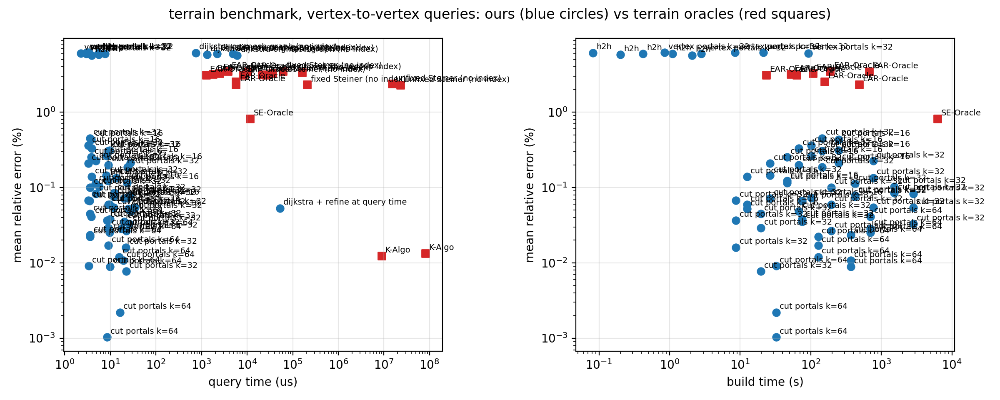

## Arbitrary-point queries

### HorseMount: 793 vertices, 1488 faces, 100 arbitrary-point queries

| method | build (s) | index (MB) | query (us) | mean err | p90 err | max err |
|---|---:|---:|---:|---:|---:|---:|
| cut portals k=16, exact MMP labels + interp, A2A interp | 15.1 | 1.10 | 252.1 | 0.272% | 0.592% | 3.58% |
| cut portals k=16, exact MMP labels + interp, A2A snap | 15.1 | 1.10 | 253.9 | 1.830% | 4.599% | 20.32% |
| cut portals k=16, exact MMP labels + model interp, A2A interp | 12.5 | 0.82 | 360.0 | 0.198% | 0.468% | 3.47% |
| cut portals k=16, exact MMP labels + model interp, A2A snap | 12.5 | 0.82 | 353.4 | 1.769% | 3.831% | 20.32% |
| cut portals k=32, exact MMP labels + interp, A2A interp | 24.6 | 1.73 | 251.5 | 0.188% | 0.397% | 3.64% |
| cut portals k=32, exact MMP labels + interp, A2A snap | 24.6 | 1.73 | 267.0 | 1.762% | 4.465% | 20.32% |
| cut portals k=32, exact MMP labels + model interp, A2A interp | 19.7 | 1.14 | 285.0 | 0.169% | 0.363% | 3.64% |
| cut portals k=32, exact MMP labels + model interp, A2A snap | 19.7 | 1.14 | 298.2 | 1.736% | 3.924% | 20.32% |
| cut portals k=32, exact MMP labels, k~|cut| + interp, A2A interp | 11.9 | 1.18 | 252.4 | 0.192% | 0.395% | 3.50% |
| cut portals k=32, exact MMP labels, k~|cut| + interp, A2A snap | 11.9 | 1.18 | 253.4 | 1.786% | 4.469% | 20.32% |
| cut portals k=32, exact MMP labels, k~|cut| + model interp, A2A interp | 8.7 | 0.85 | 339.2 | 0.171% | 0.368% | 3.47% |
| cut portals k=32, exact MMP labels, k~|cut| + model interp, A2A snap | 8.7 | 0.85 | 273.4 | 1.745% | 3.884% | 20.32% |
| cut portals k=64, exact MMP labels + interp, A2A interp | 44.9 | 2.98 | 257.9 | 0.156% | 0.342% | 3.48% |
| cut portals k=64, exact MMP labels + interp, A2A snap | 44.9 | 2.98 | 257.0 | 1.735% | 4.062% | 20.32% |
| cut portals k=64, exact MMP labels + model interp, A2A interp | 32.4 | 1.78 | 260.1 | 0.149% | 0.342% | 3.48% |
| cut portals k=64, exact MMP labels + model interp, A2A snap | 32.4 | 1.78 | 242.3 | 1.723% | 3.890% | 20.32% |
| EAR-Oracle sp=5 eps=0.2 | 23.6 | 371.00 | 1297.7 | 5.408% | 8.375% | 84.93% |
| fixed Steiner (no index) sp=5 | 0.0 | 0.00 | 12026.5 | 5.390% | 8.375% | 84.93% |
| MMP (exact, no index) | 0.0 | 0.00 | 14427.6 | -0.000% | 0.000% | 0.00% |
| K-Algo eps=0.2 | 0.0 | 0.00 | 2707432.9 | 3.732% | 4.901% | 160.79% |

### BigMount: 1440 vertices, 2772 faces, 100 arbitrary-point queries

| method | build (s) | index (MB) | query (us) | mean err | p90 err | max err |
|---|---:|---:|---:|---:|---:|---:|
| cut portals k=16, exact MMP labels + interp, A2A interp | 57.0 | 2.21 | 208.0 | 0.297% | 0.758% | 2.69% |
| cut portals k=16, exact MMP labels + interp, A2A snap | 57.0 | 2.21 | 207.7 | 1.722% | 3.821% | 20.20% |
| cut portals k=16, exact MMP labels + model interp, A2A interp | 46.1 | 1.60 | 317.8 | 0.222% | 0.425% | 2.68% |
| cut portals k=16, exact MMP labels + model interp, A2A snap | 46.1 | 1.60 | 321.0 | 1.652% | 3.380% | 20.20% |
| cut portals k=32, exact MMP labels + interp, A2A interp | 93.6 | 3.53 | 213.1 | 0.184% | 0.554% | 2.68% |
| cut portals k=32, exact MMP labels + interp, A2A snap | 93.6 | 3.53 | 208.8 | 1.643% | 3.596% | 20.20% |
| cut portals k=32, exact MMP labels + model interp, A2A interp | 75.7 | 2.27 | 269.3 | 0.159% | 0.391% | 2.68% |
| cut portals k=32, exact MMP labels + model interp, A2A snap | 75.7 | 2.27 | 271.8 | 1.614% | 3.229% | 20.20% |
| cut portals k=32, exact MMP labels, k~|cut| + interp, A2A interp | 36.8 | 1.93 | 216.3 | 0.344% | 0.658% | 5.45% |
| cut portals k=32, exact MMP labels, k~|cut| + interp, A2A snap | 36.8 | 1.93 | 216.8 | 1.783% | 3.940% | 20.20% |
| cut portals k=32, exact MMP labels, k~|cut| + model interp, A2A interp | 26.5 | 1.44 | 277.6 | 0.189% | 0.443% | 2.68% |
| cut portals k=32, exact MMP labels, k~|cut| + model interp, A2A snap | 26.5 | 1.44 | 241.9 | 1.643% | 3.248% | 20.20% |
| cut portals k=64, exact MMP labels + interp, A2A interp | 167.8 | 6.18 | 218.8 | 0.136% | 0.268% | 2.68% |
| cut portals k=64, exact MMP labels + interp, A2A snap | 167.8 | 6.18 | 206.9 | 1.575% | 3.233% | 20.20% |
| cut portals k=64, exact MMP labels + model interp, A2A interp | 128.2 | 3.63 | 238.0 | 0.127% | 0.268% | 2.68% |
| cut portals k=64, exact MMP labels + model interp, A2A snap | 128.2 | 3.63 | 232.1 | 1.569% | 3.160% | 20.20% |
| EAR-Oracle sp=5 eps=0.2 | 52.9 | 335.00 | 1786.9 | 4.556% | 5.940% | 15.93% |
| fixed Steiner (no index) sp=5 | 0.0 | 0.00 | 23302.7 | 4.541% | 5.940% | 15.93% |
| MMP (exact, no index) | 0.0 | 0.00 | 29050.8 | -0.000% | 0.000% | 0.00% |
| K-Algo eps=0.2 | 0.0 | 0.00 | 5934479.8 | 1.874% | 3.821% | 20.22% |

### HeadlightMount: 2470 vertices, 4771 faces, 100 arbitrary-point queries

| method | build (s) | index (MB) | query (us) | mean err | p90 err | max err |
|---|---:|---:|---:|---:|---:|---:|
| cut portals k=16, exact MMP labels + interp, A2A interp | 165.4 | 4.08 | 180.5 | 0.213% | 0.557% | 2.82% |
| cut portals k=16, exact MMP labels + interp, A2A snap | 165.4 | 4.08 | 187.7 | 1.126% | 2.220% | 5.83% |
| cut portals k=16, exact MMP labels + model interp, A2A interp | 101.1 | 2.87 | 256.6 | 0.142% | 0.384% | 1.14% |
| cut portals k=16, exact MMP labels + model interp, A2A snap | 101.1 | 2.87 | 252.0 | 1.105% | 2.298% | 5.84% |
| cut portals k=32, exact MMP labels + interp, A2A interp | 255.5 | 6.68 | 187.0 | 0.097% | 0.181% | 1.85% |
| cut portals k=32, exact MMP labels + interp, A2A snap | 255.5 | 6.68 | 184.9 | 1.032% | 2.038% | 5.85% |
| cut portals k=32, exact MMP labels + model interp, A2A interp | 194.2 | 4.20 | 237.5 | 0.081% | 0.161% | 1.14% |
| cut portals k=32, exact MMP labels + model interp, A2A snap | 194.2 | 4.20 | 237.5 | 1.034% | 2.032% | 5.87% |
| cut portals k=32, exact MMP labels, k~|cut| + interp, A2A interp | 86.8 | 3.35 | 183.3 | 0.259% | 0.446% | 7.93% |
| cut portals k=32, exact MMP labels, k~|cut| + interp, A2A snap | 86.8 | 3.35 | 185.4 | 1.179% | 2.270% | 7.48% |
| cut portals k=32, exact MMP labels, k~|cut| + model interp, A2A interp | 68.0 | 2.49 | 275.8 | 0.123% | 0.372% | 1.16% |
| cut portals k=32, exact MMP labels, k~|cut| + model interp, A2A snap | 68.0 | 2.49 | 284.1 | 1.086% | 2.210% | 6.33% |
| cut portals k=64, exact MMP labels + interp, A2A interp | 470.1 | 11.87 | 185.1 | 0.079% | 0.149% | 1.32% |
| cut portals k=64, exact MMP labels + interp, A2A snap | 470.1 | 11.87 | 182.4 | 1.022% | 2.035% | 5.84% |
| cut portals k=64, exact MMP labels + model interp, A2A interp | 370.5 | 6.86 | 213.7 | 0.067% | 0.149% | 1.12% |
| cut portals k=64, exact MMP labels + model interp, A2A snap | 370.5 | 6.86 | 223.5 | 1.019% | 2.035% | 5.84% |
| EAR-Oracle sp=5 eps=0.2 | 122.7 | 556.00 | 2855.0 | 4.180% | 5.493% | 28.84% |
| fixed Steiner (no index) sp=5 | 0.0 | 0.00 | 40197.4 | 4.132% | 5.483% | 28.84% |
| MMP (exact, no index) | 0.0 | 0.00 | 71023.3 | 0.000% | 0.000% | 0.00% |
| K-Algo eps=0.2 (20 queries) | 0.0 | 0.00 | 13866907.7 | 2.180% | 1.827% | 28.84% |

### RobinsonMountain: 3696 vertices, 7200 faces, 100 arbitrary-point queries

| method | build (s) | index (MB) | query (us) | mean err | p90 err | max err |
|---|---:|---:|---:|---:|---:|---:|
| cut portals k=16, exact MMP labels + interp, A2A interp | 320.7 | 6.47 | 165.0 | 0.382% | 0.843% | 4.04% |
| cut portals k=16, exact MMP labels + interp, A2A snap | 320.7 | 6.47 | 165.2 | 1.391% | 2.902% | 11.26% |
| cut portals k=16, exact MMP labels + model interp, A2A interp | 248.0 | 4.66 | 298.8 | 0.269% | 0.665% | 2.40% |
| cut portals k=16, exact MMP labels + model interp, A2A snap | 248.0 | 4.66 | 306.6 | 1.323% | 2.682% | 11.43% |
| cut portals k=32, exact MMP labels + interp, A2A interp | 304.2 | 10.32 | 98.6 | 0.167% | 0.389% | 1.19% |
| cut portals k=32, exact MMP labels + interp, A2A snap | 304.2 | 10.32 | 98.1 | 1.202% | 2.595% | 11.26% |
| cut portals k=32, exact MMP labels + model interp, A2A interp | 421.0 | 6.62 | 289.3 | 0.151% | 0.347% | 0.98% |
| cut portals k=32, exact MMP labels + model interp, A2A snap | 421.0 | 6.62 | 279.8 | 1.207% | 2.649% | 11.27% |
| cut portals k=32, exact MMP labels, k~|cut| + interp, A2A interp | 110.3 | 5.44 | 99.8 | 0.303% | 0.755% | 3.69% |
| cut portals k=32, exact MMP labels, k~|cut| + interp, A2A snap | 110.3 | 5.44 | 99.6 | 1.347% | 2.787% | 11.93% |
| cut portals k=32, exact MMP labels, k~|cut| + model interp, A2A interp | 145.6 | 4.12 | 317.7 | 0.218% | 0.466% | 1.58% |
| cut portals k=32, exact MMP labels, k~|cut| + model interp, A2A snap | 145.6 | 4.12 | 250.4 | 1.277% | 2.745% | 11.70% |
| cut portals k=64, exact MMP labels + interp, A2A interp | 526.6 | 18.02 | 100.3 | 0.102% | 0.281% | 0.87% |
| cut portals k=64, exact MMP labels + interp, A2A snap | 526.6 | 18.02 | 98.9 | 1.157% | 2.483% | 11.26% |
| cut portals k=64, exact MMP labels + model interp, A2A interp | 702.6 | 10.53 | 192.5 | 0.098% | 0.232% | 0.87% |
| cut portals k=64, exact MMP labels + model interp, A2A snap | 702.6 | 10.53 | 186.8 | 1.155% | 2.486% | 11.26% |
| EAR-Oracle sp=5 eps=0.2 | 191.5 | 1447.00 | 4171.4 | 4.374% | 6.591% | 22.49% |
| fixed Steiner (no index) sp=5 | 0.0 | 0.00 | 63970.3 | 4.335% | 6.590% | 22.51% |
| K-Algo eps=0.2 (20 queries) | 0.0 | 0.00 | 19239027.9 | 1.482% | 2.888% | 11.18% |
| MMP (exact, no index) | 0.0 | 0.00 | 106137.5 | -0.000% | 0.000% | 0.00% |

### Gunnison10k: 9610 vertices, 18819 faces, 100 arbitrary-point queries

| method | build (s) | index (MB) | query (us) | mean err | p90 err | max err |
|---|---:|---:|---:|---:|---:|---:|
| cut portals k=32, exact MMP labels + interp, A2A interp | 1990.8 | 31.35 | 102.8 | 0.123% | 0.146% | 5.68% |
| cut portals k=32, exact MMP labels + interp, A2A snap | 1990.8 | 31.35 | 123.8 | 0.621% | 1.350% | 3.27% |
| cut portals k=32, exact MMP labels + model interp, A2A interp | 2837.7 | 19.27 | 303.1 | 0.059% | 0.134% | 1.10% |
| cut portals k=32, exact MMP labels + model interp, A2A snap | 2837.7 | 19.27 | 298.8 | 0.595% | 1.350% | 3.21% |
| cut portals k=32, exact MMP labels, k~|cut| + interp, A2A interp | 666.0 | 14.65 | 128.8 | 0.307% | 0.468% | 10.54% |
| cut portals k=32, exact MMP labels, k~|cut| + interp, A2A snap | 666.0 | 14.65 | 115.9 | 0.784% | 1.457% | 10.32% |
| cut portals k=32, exact MMP labels, k~|cut| + model interp, A2A interp | 765.8 | 10.70 | 308.1 | 0.076% | 0.183% | 1.14% |
| cut portals k=32, exact MMP labels, k~|cut| + model interp, A2A snap | 765.8 | 10.70 | 296.9 | 0.620% | 1.400% | 3.20% |
| EAR-Oracle sp=5 eps=0.2 | 710.9 | 740.00 | 10488.1 | 3.545% | 4.445% | 11.80% |
| fixed Steiner (no index) sp=5 | 0.0 | 0.00 | 185737.7 | 3.474% | 4.411% | 11.80% |
| K-Algo eps=0.2 (20 queries) | 0.0 | 0.00 | 68633258.7 | 0.752% | 1.369% | 3.22% |
| MMP (exact, no index) | 0.0 | 0.00 | 480790.7 | 0.000% | 0.000% | 0.00% |

### GunnisonForest100k: 100511 vertices, 199998 faces, 100 arbitrary-point queries

| method | build (s) | index (MB) | query (us) | mean err | p90 err | max err |
|---|---:|---:|---:|---:|---:|---:|
| cut portals k=32, exact MMP labels + model interp, A2A interp | 83463.6 | 252.22 | 151.7 | 0.047% | 0.142% | 0.35% |
| cut portals k=32, exact MMP labels + model interp, A2A snap | 83463.6 | 252.22 | 149.2 | 0.289% | 0.412% | 5.31% |
| cut portals k=32, exact MMP labels, k~|cut| + model interp, A2A interp | 16544.9 | 130.19 | 185.5 | 0.069% | 0.206% | 0.68% |
| cut portals k=32, exact MMP labels, k~|cut| + model interp, A2A snap | 16544.9 | 130.19 | 180.1 | 0.311% | 0.487% | 5.04% |
| fixed Steiner (no index) sp=5 | 0.0 | 0.00 | 2584508.3 | 2.985% | 3.681% | 7.05% |
| MMP (exact, no index) | 0.0 | 0.00 | 23815590.2 | -0.000% | 0.000% | 0.00% |

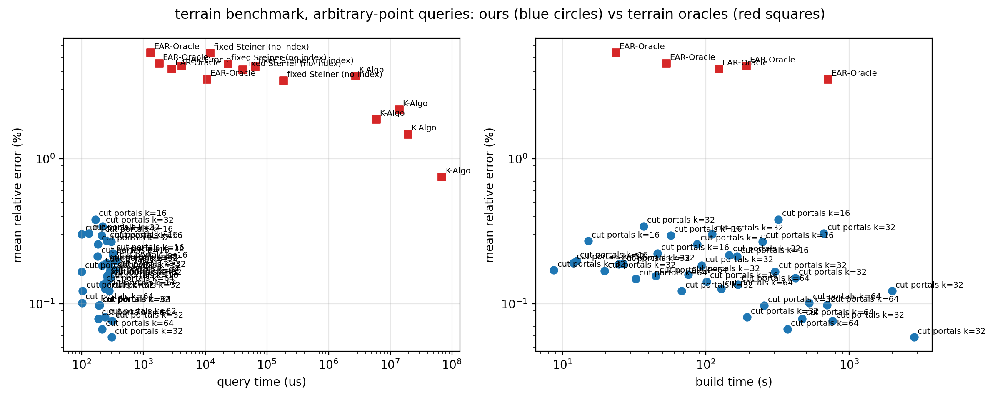

## Weighted terrain (HorseMount, face costs uniform in (1, 5); errors vs. the best path any method found)

### HorseMount: 793 vertices, 1488 faces, 100 vertex-to-vertex, weighted faces queries (errors relative to the best path any method found)

| method | build (s) | index (MB) | query (us) | mean err | p90 err | max err |
|---|---:|---:|---:|---:|---:|---:|
| dijkstra on mesh graph (no index) | 0.0 | 0.00 | 552.7 | 9.136% | 13.150% | 204.22% |
| h2h | 0.1 | 0.65 | 3.5 | 9.136% | 13.150% | 204.22% |
| vertex portals k=32 | 0.6 | 0.77 | 1.9 | 9.136% | 13.150% | 204.22% |
| cut portals k=32, refined labels (rounds=1, seg=12) | 971.8 | 1.47 | 4.0 | 8.601% | 12.421% | 204.22% |
| cut portals k=32, refined labels (rounds=1, seg=12) + interp | 971.8 | 1.47 | 8.4 | 8.588% | 12.421% | 204.22% |
| cut portals k=32, refined labels (rounds=1, seg=12) + model interp | 971.8 | 1.47 | 15.5 | 8.600% | 12.421% | 204.22% |
| dijkstra + refine at query time (rounds=1, seg=12) | 0.0 | 0.00 | 17416.6 | 7.681% | 15.619% | 50.13% |
| dijkstra + refine at query time (rounds=3, seg=40) | 0.0 | 0.00 | 44648.2 | 7.292% | 11.765% | 204.22% |
| EAR-Oracle sp=5 eps=0.2 | 16.8 | 389.00 | 746.1 | 0.209% | 0.592% | 3.50% |
| fixed Steiner (no index) sp=5 | 0.0 | 0.00 | 7360.4 | 0.205% | 0.580% | 3.50% |
| unfixed Steiner (no index) eps=0.05 (30 queries) | 0.0 | 0.00 | 11653059.6 | 0.041% | 0.011% | 0.89% |

In [3]:
from IPython.display import Markdown, Image, display
MESHES = ["HorseMount", "BigMount", "HeadlightMount", "RobinsonMountain", "Gunnison10k", "GunnisonForest100k"]
for kind in ("V2V", "A2A"):
    display(Markdown(f"## {'Vertex-to-vertex' if kind == 'V2V' else 'Arbitrary-point'} queries"))
    for mesh in MESHES:
        try:
            display(Markdown(terrain_report.table(mesh, kind=kind)))
        except (FileNotFoundError, IndexError):
            print(f"{mesh}: no results yet")
    display(Image(terrain_report.pareto(MESHES[:5], path=f"results/terrain_pareto{'' if kind == 'V2V' else '_a2a'}.png", kind=kind)))
display(Markdown("## Weighted terrain (HorseMount, face costs uniform in (1, 5); errors vs. the best path any method found)"))
display(Markdown(terrain_report.table("HorseMount", kind="W2V")))


### Why the budget is uniform across the tree on a terrain

With `scale_k` the deep cuts get `k_min = 4` portals. The pairs they separate are *close* pairs, and
the portal term of the error bound (`notes/error_bound.md`) is
$\varepsilon \lesssim \frac{h^2}{8d}\left(\frac1{r_s}+\frac1{r_t}\right) \sim (h/d)^2$: it is scale-free only if the
portal gap $h$ shrinks with the region, i.e. if every cut has the same number of portals. Measured on
BigMount (400 random pairs, interpolated):

| LCS depth | pairs | mean $d$ (km) | error, `k~|cut|` (portals) | error, uniform k=32 |
|---|---|---|---|---|
| 0 | 183 | 4.7 | 0.073% (32) | 0.073% |
| 1 | 113 | 3.5 | 0.124% (18) | 0.044% |
| 2 | 56 | 2.5 | 0.166% (16) | 0.016% |
| 3 | 25 | 2.0 | 0.277% (11) | 0.000% |
| 4 | 12 | 1.2 | 0.407% (9) | 0.020% |
| 5–6 | 11 | 0.7 | 1.1% (6) | 0.003% |

Mean error 0.150% → 0.049% for 4.5× the portals. The remaining outliers turned out to be pairs with an
**endpoint close to the cut** at any distance: there $d(s,x)\approx\sqrt{r_s^2+(x-x_s)^2}$ along the cut has
curvature $1/r_s\sim 1/h$ and the parabola through three samples cannot resolve the crossing. The
`model interp` rows subtract that term (feet precomputed at build), fit only the smooth remainder and
minimise the sum by bracketed Newton (`notes/error_bound.md` §5b): HorseMount k=32, 2000 pairs, mean
0.037% → 0.019%, p99 0.73% → 0.27%, max 4.2% → 1.2%, at ~20 µs; it helps less on the steeper meshes
(RobinsonMountain: unchanged). The exact `halo_rings` table covers the few-edge pairs (+0.4 MB).

The general-manifold pipeline (refined graph paths as labels) also runs on a terrain, at a very
different price: every energy evaluation is an exact face walk, so a label costs ~50–140 ms instead of
~5 ms on an analytic metric, and the build of the same index is 60× slower than with exact labels for
a worse error (HorseMount, single thread: 1527 s and 0.085% vs 24.6 s and 0.029%).

**Arbitrary points.** Attaching a point through the vertices of its face is first order in the edge
length whatever the vertex distances are (exact vertex distances give the same 2%): the corner at the
vertex is the error, and the K-Algo harness shows the identical failure (its 160.8% worst case on
HorseMount is the same pair as our `snap` worst case). Interpolating the vertex-pair oracle bilinearly
over the two faces is second order, $O(\text{edge}^2/d)$, which is why its error falls with distance
(HorseMount, k=32: 1.0% under 1 km, 0.15% at 2–3 km, 0.04% beyond 5 km) and why pairs within a few
faces of each other are answered by an exact local sweep instead. EAR-Oracle's own arbitrary-point
error is *larger* than its vertex-pair error (its endpoint attachment goes through Steiner points), so
the gap widens there: 0.08–0.17% (ours, k=32) against 3.5–5.4% (EAR) and 0.8–3.7% (K-Algo).

**Weighted terrain.** With face costs in $(1,5)$ there is no exact solver, so labels are refined graph
paths and the reference is the best path any method found (their K-Algo ignores the weights and is
excluded). The vertex mesh graph is the wrong skeleton there: weighted geodesics refract at every edge and
hug cheap ones, the competitors' Steiner base graph finds corridors the vertex graph cannot (EAR 0.2%,
unfixed Steiner 0.04%), and refinement, being local, inherits the graph's 9% (8.6% after refinement;
portals at edge crossings do not change that). The remedy is the same index on a Steiner base graph.
